# Hito 2 — ABB IRB120

## Objetivo
Implementar un pipeline que conecte una pose deseada con:
- Cinemática inversa analítica.
- Validación mediante cinemática directa.
- Selección de una configuración admisible.
- Trayectoria articular LSPB.
- Jacobiano y análisis de singularidades.
- Dinámica reducida 1R y torque.

## Convenciones
- Longitudes internas en metros.
- Ángulos internos en radianes.
- Tiempo en segundos.
- Pose objetivo del TCP expresada respecto a la base.
Versión 3 — candidata a entrega. Conserva las versiones anteriores por separado.


In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

print("Python utilizado:", sys.executable)
print("NumPy:", np.__version__)
print("Entorno del Hito 2 listo.")

Python utilizado: /usr/bin/python3
NumPy: 2.1.3
Entorno del Hito 2 listo.


## 1. Modelo cinemático del ABB IRB120

Se utiliza la convención Denavit–Hartenberg estándar:

A_i = Rz(theta_i) Tz(d_i) Tx(a_i) Rx(alpha_i)

Los ángulos articulares q se expresan en radianes.
La segunda articulación incorpora el desfase theta_2 = q_2 - pi/2.

La cinemática directa termina en el marco 6.
El TCP se obtiene mediante una transformación fija adicional.

La longitud de herramienta de 0.095 m es un supuesto provisional
del ejercicio, no una dimensión certificada de una herramienta ABB.

In [2]:
# Dimensiones de nuestro modelo [m].
D1 = 0.290
A2 = 0.270
A3 = 0.070
D4 = 0.302
D6 = 0.072

# Herramienta provisional: desplazamiento sobre +z6 [m].
L_TCP = 0.095

T_6_TCP = np.eye(4)
T_6_TCP[2, 3] = L_TCP

# Límites del modelo que venimos utilizando [rad].
# En el informe debemos conservar su procedencia.
Q_MIN = np.array([
    -2.87979,
    -1.91986,
    -1.91986,
    -2.79253,
    -2.094395,
    -6.98132,
])

Q_MAX = np.array([
    2.87979,
    1.91986,
    1.22173,
    2.79253,
    2.094395,
    6.98132,
])

print("Modelo y herramienta definidos.")
print("Límites inferiores [grados]:", np.rad2deg(Q_MIN))
print("Límites superiores [grados]:", np.rad2deg(Q_MAX))

Modelo y herramienta definidos.
Límites inferiores [grados]: [-164.999813 -109.999875 -109.999875 -160.000183 -119.999994 -400.000171]
Límites superiores [grados]: [164.999813 109.999875  69.999973 160.000183 119.999994 400.000171]


In [3]:
def matriz_DH(theta, d, a, alpha):
    """Transformación D-H estándar."""
    ct = np.cos(theta)
    st = np.sin(theta)
    ca = np.cos(alpha)
    sa = np.sin(alpha)

    return np.array([
        [ct, -st * ca,  st * sa, a * ct],
        [st,  ct * ca, -ct * sa, a * st],
        [0.0,     sa,       ca,      d],
        [0.0,    0.0,      0.0,    1.0],
    ])


def tabla_DH(q):
    """Filas D-H: theta, d, a, alpha. Ángulos en radianes."""
    q = np.asarray(q, dtype=float)

    if q.shape != (6,) or not np.all(np.isfinite(q)):
        raise ValueError("q debe contener seis ángulos finitos.")

    return np.array([
        [q[0],             D1, 0.0, -np.pi / 2],
        [q[1] - np.pi / 2, 0.0, A2,        0.0],
        [q[2],            0.0, A3, -np.pi / 2],
        [q[3],             D4, 0.0,  np.pi / 2],
        [q[4],            0.0, 0.0, -np.pi / 2],
        [q[5],             D6, 0.0,        0.0],
    ])


def transformaciones_acumuladas(q):
    """
    Devuelve [T_00, T_01, ..., T_06].
    También servirá para construir el Jacobiano.
    """
    transformaciones = [np.eye(4)]

    for parametros in tabla_DH(q):
        siguiente = transformaciones[-1] @ matriz_DH(*parametros)
        transformaciones.append(siguiente)

    return transformaciones


def cinematica_directa(q):
    """Pose del marco 6 respecto a la base."""
    return transformaciones_acumuladas(q)[-1]


def cinematica_tcp(q):
    """Pose del TCP respecto a la base."""
    return cinematica_directa(q) @ T_6_TCP


print("Funciones de cinemática directa listas.")

Funciones de cinemática directa listas.


## 2. Entradas del caso

T_d representa la pose deseada del TCP respecto a la base:
- Su bloque 3x3 contiene la orientación.
- Su última columna contiene la posición en metros.

La configuración inicial y los parámetros temporales se establecen
para planificar el movimiento posterior.

Al cambiar la pose objetivo, se deben ejecutar nuevamente todas
las celdas de cálculo que dependen de ella.

In [4]:
# Pose deseada del TCP respecto a la base.
T_d = np.array([
    [1.0,  0.0,  0.0, 0.437],
    [0.0, -1.0,  0.0, 0.000],
    [0.0,  0.0, -1.0, 0.193 + 0.135 * np.sqrt(3)],
    [0.0,  0.0,  0.0, 1.000],
])

# Configuración inicial elegida para el movimiento [rad].
q_inicial = np.deg2rad([0, 0, 0, 0, 0, 0])

# Parámetros de planificación LSPB.
TIEMPO_TOTAL = 3.0
FACTOR_ACELERACION = 1.125

print("Pose deseada del TCP:")
print(T_d)

Pose deseada del TCP:
[[ 1.        0.        0.        0.437   ]
 [ 0.       -1.        0.        0.      ]
 [ 0.        0.       -1.        0.426827]
 [ 0.        0.        0.        1.      ]]


In [5]:
def validar_transformacion(T, nombre="T", tolerancia=1e-8):
    """Comprueba estructura homogénea y rotación válida."""
    T = np.asarray(T, dtype=float)

    if T.shape != (4, 4):
        raise ValueError(f"{nombre} debe ser una matriz 4x4.")

    if not np.all(np.isfinite(T)):
        raise ValueError(f"{nombre} contiene valores no finitos.")

    if not np.allclose(
        T[3], [0, 0, 0, 1], atol=tolerancia, rtol=0
    ):
        raise ValueError(f"{nombre}: última fila incorrecta.")

    R = T[:3, :3]

    if not np.allclose(
        R.T @ R, np.eye(3), atol=tolerancia, rtol=0
    ):
        raise ValueError(f"{nombre}: la rotación no es ortonormal.")

    if not np.isclose(
        np.linalg.det(R), 1.0, atol=tolerancia, rtol=0
    ):
        raise ValueError(f"{nombre}: el determinante de R debe ser +1.")


def inversa_rigida(T):
    """Inversa de una transformación rígida previamente validada."""
    R = T[:3, :3]
    p = T[:3, 3]

    inversa = np.eye(4)
    inversa[:3, :3] = R.T
    inversa[:3, 3] = -R.T @ p

    return inversa


# Borramos resultados del caso anterior antes de recalcular.
T_06_d = None
p_W = None

validar_transformacion(T_d, "T_d")
validar_transformacion(T_6_TCP, "T_6_TCP")

# Convertir la pose objetivo del TCP a pose del marco 6.
T_06_d = T_d @ inversa_rigida(T_6_TCP)

# Centro de muñeca, expresado en la base.
p_W = T_06_d[:3, 3] - D6 * T_06_d[:3, 2]

print("POSE DESEADA DEL MARCO 6:")
print(T_06_d)

print("\nCENTRO DE MUÑECA [m]:")
print(p_W)

# Verificar que al reponer la herramienta recuperamos T_d.
assert np.allclose(
    T_06_d @ T_6_TCP,
    T_d,
    atol=1e-10,
    rtol=0,
)

print("\nConversión TCP → marco 6 → centro de muñeca correcta.")

POSE DESEADA DEL MARCO 6:
[[ 1.        0.        0.        0.437   ]
 [ 0.       -1.        0.        0.      ]
 [ 0.        0.       -1.        0.521827]
 [ 0.        0.        0.        1.      ]]

CENTRO DE MUÑECA [m]:
[0.437    0.       0.593827]

Conversión TCP → marco 6 → centro de muñeca correcta.


## 3. Cinemática inversa del brazo

Las primeras tres articulaciones colocan el centro de muñeca.

Partimos del centro de muñeca calculado desde la pose objetivo:

$$
p_W = [x_W,\ y_W,\ z_W]^T.
$$

Definimos:

$$
r=\sqrt{x_W^2+y_W^2}, \qquad h=z_W-d_1.
$$

Las dos ramas de base corresponden a:

- Rama A: radio firmado positivo, rho = r.
- Rama B: radio firmado negativo, rho = -r.

Combinamos los desplazamientos a3 y d4:

$$
L=\sqrt{a_3^2+d_4^2},
\qquad
\beta=\operatorname{atan2}(d_4,a_3).
$$

Definimos delta = q3 + beta y calculamos:

$$
C=\cos\delta=
\frac{r^2+h^2-a_2^2-L^2}{2a_2L}.
$$

Si |C| > 1, el centro de muñeca no es geométricamente alcanzable.

Para cada rama de base, las dos ramas del codo son:

$$
\delta_\pm =
\operatorname{atan2}\left(\pm\sqrt{1-C^2},C\right).
$$

Los ángulos restantes se obtienen mediante:

$$
q_3=\delta-\beta
$$

$$
q_2=
\operatorname{atan2}(\rho,h)
-
\operatorname{atan2}(L\sin\delta,\ a_2+L\cos\delta).
$$

Cada candidato se verifica mediante cinemática directa y se compara
con los límites articulares. En esta etapa todavía no se resuelve
la orientación del TCP.


In [6]:
def normalizar(angulo):
    """Representa ángulos en el intervalo [-pi, pi)."""
    return (np.asarray(angulo) + np.pi) % (2.0 * np.pi) - np.pi


def resolver_brazo(p, q1_libre=0.0):
    """
    Calcula las ramas de q1, q2, q3 a partir del centro de muñeca.

    Entrada:
        p: centro de muñeca en la base [m].

    Salida:
        Lista de diccionarios con nombre de rama y q123 [rad].

    Alcance actual:
        En el eje devuelve una sección de la familia con q1=q1_libre.
        La IK completa estudia después los intervalos de q1.
    """
    p = np.asarray(p, dtype=float)

    if p.shape != (3,) or not np.all(np.isfinite(p)):
        raise ValueError("El centro de muñeca debe contener tres valores finitos.")

    x, y, z = p

    r = np.hypot(x, y)
    h = z - D1

    L = np.hypot(A3, D4)
    beta = np.arctan2(D4, A3)

    C = (r**2 + h**2 - A2**2 - L**2) / (2.0 * A2 * L)

    # Primero comprobamos el alcance geométrico.
    if abs(C) > 1.0 + 1e-12:
        raise ValueError(
            f"Centro de muñeca fuera del alcance geométrico: C = {C:.6f}"
        )

    # Corregir únicamente excesos diminutos por redondeo.
    C = np.clip(C, -1.0, 1.0)
    seno_abs = np.sqrt(max(0.0, 1.0 - C**2))

    soluciones = []

    bases = [("E", 1)] if r < 1e-12 else [("A", 1), ("B", -1)]
    for nombre_base, signo_base in bases:
        q1 = q1_libre if r < 1e-12 else np.arctan2(y, x)

        if signo_base == -1:
            q1 += np.pi

        rho = signo_base * r

        for nombre_codo, signo_codo in [("+", 1), ("-", -1)]:
            delta = np.arctan2(signo_codo * seno_abs, C)

            q3 = delta - beta

            q2 = (
                np.arctan2(rho, h)
                - np.arctan2(
                    L * np.sin(delta),
                    A2 + L * np.cos(delta),
                )
            )

            q123 = normalizar(np.array([q1, q2, q3]))

            soluciones.append({
                "rama": nombre_base + nombre_codo,
                "q123": q123,
            })

    return soluciones


def centro_muneca_por_fk(q123):
    """Obtiene el origen del marco 4 usando la cadena D-H."""
    q_completo = np.r_[q123, 0.0, 0.0, 0.0]

    # La lista contiene T_00, T_01, ..., T_06.
    T_04 = transformaciones_acumuladas(q_completo)[4]

    return T_04[:3, 3]


print("Funciones de cinemática inversa del brazo listas.")


Funciones de cinemática inversa del brazo listas.


In [7]:
# Limpiar resultados de una ejecución anterior.
soluciones_brazo = []
registro_brazo = []
q_final = None

if p_W is None:
    raise ValueError("Primero debes calcular el centro de muñeca.")

# Entrada tomada directamente del paso anterior.
soluciones_brazo = resolver_brazo(p_W, q_inicial[0])

print("Centro de muñeca objetivo [m]:")
print(p_W)

print("\nRESULTADOS DE LA INVERSA DEL BRAZO\n")
print(
    f"{'Rama':<6}"
    f"{'q1 [°]':>13}"
    f"{'q2 [°]':>13}"
    f"{'q3 [°]':>13}"
    f"{'Error [m]':>15}  "
    f"Límites"
)
print("-" * 88)

for solucion in soluciones_brazo:
    nombre = solucion["rama"]
    q123 = solucion["q123"]

    # Comprobación independiente mediante la cadena D-H.
    p_calculado = centro_muneca_por_fk(q123)
    error = np.linalg.norm(p_calculado - p_W)

    dentro = (
        (q123 >= Q_MIN[:3])
        & (q123 <= Q_MAX[:3])
    )

    fuera = [
        f"J{j+1}"
        for j in range(3)
        if not dentro[j]
    ]

    estado = "CUMPLE" if not fuera else "Fuera: " + ", ".join(fuera)

    registro_brazo.append({
        "rama": nombre,
        "q123": q123.copy(),
        "p_W_fk": p_calculado.copy(),
        "error_posicion_m": float(error),
        "cumple_limites_brazo": bool(np.all(dentro)),
        "articulaciones_fuera": fuera,
    })

    grados = np.rad2deg(q123)

    print(
        f"{nombre:<6}"
        f"{grados[0]:>13.6f}"
        f"{grados[1]:>13.6f}"
        f"{grados[2]:>13.6f}"
        f"{error:>15.3e}  "
        f"{estado}"
    )

    if error > 1e-10:
        raise ValueError(
            f"La rama {nombre} no reproduce el centro de muñeca."
        )

print("\nTodas las ramas calculadas reproducen el centro de muñeca.")
print("Se conservan también las ramas fuera de límites para documentarlas.")
if np.hypot(p_W[0], p_W[1]) < 1e-12:
    print("Caso axial: esta tabla usa q1 inicial como sección de la familia.")
    print("La orientación y los límites se examinan en la IK completa.")


Centro de muñeca objetivo [m]:
[0.437    0.       0.593827]

RESULTADOS DE LA INVERSA DEL BRAZO

Rama         q1 [°]       q2 [°]       q3 [°]      Error [m]  Límites
----------------------------------------------------------------------------------------
A+         0.000000    30.000000   -30.000000      1.241e-16  CUMPLE
A-         0.000000    80.381623  -123.899943      1.241e-16  Fuera: J3
B+      -180.000000   -80.381623   -30.000000      7.719e-17  Fuera: J1
B-      -180.000000   -30.000000  -123.899943      1.352e-16  Fuera: J1, J3

Todas las ramas calculadas reproducen el centro de muñeca.
Se conservan también las ramas fuera de límites para documentarlas.


### Caso axial
El centro de muñeca es $p_W=p_{06}-d_6 R_{06}\hat z$.
En nuestro modelo:
$$x_W=\rho\cos q_1,\qquad y_W=\rho\sin q_1,$$
$$\rho=a_2\sin q_2+a_3\sin(q_2+q_3)+d_4\cos(q_2+q_3),$$
$$h=z_W-d_1=a_2\cos q_2+a_3\cos(q_2+q_3)-d_4\sin(q_2+q_3).$$
Si $x_W=y_W=0$, entonces $\rho=0$. Cualquier $q_1$ produce la misma
posición del centro de muñeca; usar atan2(0,0) como solución única perdería la familia.
Esto no significa que cualquier q1 respete la orientación y los límites de muñeca.

Definiendo $L=\sqrt{a_3^2+d_4^2}$, $\beta=\operatorname{atan2}(d_4,a_3)$
y $\delta=q_3+\beta$, obtenemos:
$$h^2=a_2^2+L^2+2a_2L\cos\delta,$$
$$C=\frac{h^2-a_2^2-L^2}{2a_2L},\quad
\delta=\operatorname{atan2}(\pm\sqrt{1-C^2},C),$$
$$q_3=\delta-\beta,\qquad
q_2=\operatorname{atan2}(0,h)-\operatorname{atan2}(L\sin\delta,a_2+L\cos\delta).$$
La posición deja libre $q_1\in[q_{1,\min},q_{1,\max}]$.
Para cada valor, la muñeca debe satisfacer $R_{36}(q_1)=R_{03}(q_1)^TR_{06}$.

**Cómo se trata todo el intervalo sin una malla uniforme:** con q2 y q3 fijos,
cada entrada de R36 tiene forma $a\cos q_1+b\sin q_1+c$.
Se calculan los cortes donde una junta de muñeca alcanza un límite, donde cambia
la representación angular y donde aparece una muñeca singular. Entre cortes,
las ramas regulares son continuas y su admisibilidad no cambia sin cruzar una frontera.
Por eso se prueban los cortes, un punto interior de cada intervalo y q1 inicial.

Las ecuaciones de frontera, usando índices matemáticos que empiezan en 1, son:
$$R_{33}=\cos q_{5,\mathrm{lim}},\quad
R_{23}\cos q_{4,\mathrm{lim}}-R_{13}\sin q_{4,\mathrm{lim}}=0,$$
$$-R_{32}\cos q_{6,\mathrm{lim}}-R_{31}\sin q_{6,\mathrm{lim}}=0.$$
También se incluyen $R_{33}=\pm1$ y los cortes de atan2. Los rayos opuestos
pueden añadir cortes innecesarios, pero la verificación posterior los filtra.

Cada ecuación $a\cos x+b\sin x+c=0$ se resuelve con
$M=\sqrt{a^2+b^2}$, $\psi=\operatorname{atan2}(b,a)$:
$$x=\psi\pm\arccos(-c/M)+2\pi k.$$
Si $M=0$, no hay raíces aisladas; si $|c|>M$, no hay raíces reales.
En aritmética finita se aplican tolerancias, y cada representante debe pasar FK
completa y límites. Las fronteras de J5 están especializadas al rango de este modelo,
contenido en $(-\pi,\pi)$.

**Selección:** se minimiza la distancia entre los representantes obtenidos.
Esto no prueba optimalidad global sobre la familia continua. En cambio, sí permite
buscar soluciones admisibles sin fijar arbitrariamente q1=0 y descartar otras opciones.
La familia axial puede coincidir con una singularidad de muñeca; se aplican ambos tratamientos.


## 4. Cinemática inversa de la muñeca

Para cada solución del brazo calculamos la orientación residual:

$$
R_{36}=R_{03}^{T}R_{06,d}.
$$

Con nuestra tabla D-H:

$$
r_{13}=-\cos q_4\sin q_5,\qquad
r_{23}=-\sin q_4\sin q_5,\qquad
r_{33}=\cos q_5.
$$

También:

$$
r_{31}=\sin q_5\cos q_6,\qquad
r_{32}=-\sin q_5\sin q_6.
$$

Para una muñeca no singular:

$$
s_5=\pm\sqrt{r_{13}^2+r_{23}^2},
\qquad q_5=\operatorname{atan2}(s_5,r_{33}).
$$

$$
q_4=\operatorname{atan2}(-r_{23}/s_5,-r_{13}/s_5)
$$

$$
q_6=\operatorname{atan2}(-r_{32}/s_5,r_{31}/s_5).
$$

Cada candidato completo se verifica por cinemática directa del TCP.
Luego se buscan representantes angulares dentro de los límites.

Entre las soluciones admisibles se selecciona la más cercana a la
configuración inicial, usando la norma euclídea de los desplazamientos
articulares en radianes.

### Muñeca singular: resolución analítica y elección de una solución
Con nuestra convención D-H, al sustituir $q_5=0$:
$$R_{36}=R_z(q_4)R_x(\pi/2)R_z(0)R_x(-\pi/2)R_z(q_6)
=R_z(q_4+q_6).$$
Por tanto, $\phi=\operatorname{atan2}((R_{36})_{21},(R_{36})_{11})$
y $q_4+q_6=S_k=\phi+2\pi k$. Los índices matemáticos comienzan en 1.
No dividimos por $\sin q_5$: hay una familia continua de soluciones.

Para cada entero $k$ permitido por los límites:
$$L_k=\max(q_{4,\min},S_k-q_{6,\max}),\quad
U_k=\min(q_{4,\max},S_k-q_{6,\min}).$$
Si $L_k>U_k$, esa vuelta no es admisible. En otro caso minimizamos la misma
métrica de desplazamiento que usa el notebook:
$$f(q_4)=(q_4-q_{4,i})^2+(S_k-q_4-q_{6,i})^2.$$
$$f'(q_4)=4q_4-2(q_{4,i}+S_k-q_{6,i}),\qquad f''=4>0.$$
$$q_4^*=\operatorname{clip}\left(\frac{q_{4,i}+S_k-q_{6,i}}2,L_k,U_k\right),
\qquad q_6^*=S_k-q_4^*.$$
Conservamos el mínimo de cada segmento, suficiente para seleccionar el mínimo
global de esta métrica; no son todas las infinitas configuraciones de la familia.
Por ejemplo, con referencia cero y $S=60^\circ$, resulta $q_4=q_6=30^\circ$.
Con referencia cero y $S=0$, resulta $q_4=q_6=0$.

Para $q_5=\pi$, el acoplamiento es $q_4-q_6=\phi+2\pi k$,
con $\phi=\operatorname{atan2}(-(R_{36})_{21},-(R_{36})_{11})$.
Nuestro límite de J5 excluye $\pm\pi$; conservamos una rama geométrica para
mostrar su descarte. Todas las soluciones aceptadas pasan nuevamente por FK.

**Interpretación física:** los ejes 4 y 6 coinciden cuando $q_5=0$.
Movimientos opuestos en J4 y J6 pueden dejar la pose sin cambio.
Resolver esa pose no recupera el rango del Jacobiano ni garantiza que cualquier
velocidad cartesiana sea realizable. El programa genera LSPB en espacio articular.


Para la rama regular, una vez obtenidos q4 y q5, usamos además
$B=R_z(q_4)R_x(\pi/2)R_z(q_5)R_x(-\pi/2)$ y
$R_z(q_6)=B^T R_{36}$. Recuperamos q6 con atan2 de las entradas (2,1) y (1,1).
Este despeje evita volver a dividir por un seno pequeño y mejora la estabilidad
numérica cerca de q5=0; procede de la misma igualdad analítica.


In [8]:
def resolver_muneca(R_36, referencia=None):
    """Dos ramas regulares o mínimos de las familias singulares acotadas.

    En singularidad se conservan representantes óptimos por vuelta,
    no se pretende enumerar los infinitos puntos de cada familia.
    """
    referencia = np.zeros(6) if referencia is None else np.asarray(referencia, float)
    if referencia.shape != (6,) or not np.all(np.isfinite(referencia)):
        raise ValueError("La referencia debe contener seis ángulos finitos.")
    seno_abs = np.hypot(R_36[0, 2], R_36[1, 2])
    if seno_abs < 1e-10:
        # Para q5=0: q4+q6=phi+2*pi*k.
        # Para q5=pi: q4-q6=phi+2*pi*k.
        signo = 1 if R_36[2, 2] >= 0 else -1
        q5_base = 0.0 if signo == 1 else np.pi
        phi = (np.arctan2(R_36[1, 0], R_36[0, 0]) if signo == 1
               else np.arctan2(-R_36[1, 0], -R_36[0, 0]))
        vueltas5 = range(int(np.ceil((Q_MIN[4]-q5_base)/(2*np.pi))),
                         int(np.floor((Q_MAX[4]-q5_base)/(2*np.pi)))+1)
        s_min = Q_MIN[3] + (Q_MIN[5] if signo == 1 else -Q_MAX[5])
        s_max = Q_MAX[3] + (Q_MAX[5] if signo == 1 else -Q_MIN[5])
        soluciones = []
        for k in range(int(np.ceil((s_min-phi)/(2*np.pi))),
                       int(np.floor((s_max-phi)/(2*np.pi)))+1):
            S = phi + 2*np.pi*k
            extremos = [S-signo*Q_MIN[5], S-signo*Q_MAX[5]]
            inferior = max(Q_MIN[3], min(extremos))
            superior = min(Q_MAX[3], max(extremos))
            if inferior > superior:
                continue
            q4 = np.clip((referencia[3]+S-signo*referencia[5])/2,
                         inferior, superior)
            q6 = signo*(S-q4)
            for k5 in vueltas5:
                soluciones.append({
                    "muneca": f"S{k}/{k5}",
                    "q456": np.array([q4, q5_base+2*np.pi*k5, q6]),
                })
        if not soluciones:
            # Conservar un representante geométrico para documentar
            # el descarte por límites (p. ej. q5=pi en nuestro robot).
            soluciones.append({"muneca": "S-fuera",
                               "q456": np.array([phi, q5_base, 0.0])})
        return soluciones

    soluciones = []

    for nombre, signo in [("+", 1), ("-", -1)]:
        s5 = signo * seno_abs

        q5 = np.arctan2(s5, R_36[2, 2])

        q4 = np.arctan2(
            -R_36[1, 2] / s5,
            -R_36[0, 2] / s5,
        )

        # Evitar dividir de nuevo por sin(q5) cerca de la singularidad.
        # R36 = B45 @ Rz(q6); despejamos la rotación residual.
        B45 = (matriz_DH(q4,0.,0.,np.pi/2)[:3,:3]
               @ matriz_DH(q5,0.,0.,-np.pi/2)[:3,:3])
        R6 = B45.T @ R_36
        q6 = np.arctan2(R6[1,0],R6[0,0])

        soluciones.append({
            "muneca": nombre,
            "q456": normalizar(np.array([q4, q5, q6])),
        })

    return soluciones


def errores_pose(T_calculada, T_objetivo):
    """Error de posición [m] y ángulo de error de orientación [rad]."""
    error_p = np.linalg.norm(
        T_calculada[:3, 3] - T_objetivo[:3, 3]
    )

    R_error = T_objetivo[:3, :3].T @ T_calculada[:3, :3]

    vector = np.array([
        R_error[2, 1] - R_error[1, 2],
        R_error[0, 2] - R_error[2, 0],
        R_error[1, 0] - R_error[0, 1],
    ])

    seno = np.linalg.norm(vector) / 2.0
    coseno = np.clip((np.trace(R_error) - 1.0) / 2.0, -1.0, 1.0)

    error_R = np.arctan2(seno, coseno)

    return float(error_p), float(error_R)


print("Funciones de muñeca y verificación de pose listas.")


Funciones de muñeca y verificación de pose listas.


In [9]:
from itertools import product


def representantes_admisibles(q):
    """
    Devuelve representantes q + 2*pi*k dentro de Q_MIN y Q_MAX.

    Retorna:
        representantes: lista de vectores articulares.
        fuera: articulaciones sin ningún representante permitido.
    """
    opciones = []
    fuera = []

    for j, angulo in enumerate(q):
        k_min = int(np.ceil((Q_MIN[j] - 1e-10 - angulo) / (2.0 * np.pi)))
        k_max = int(np.floor((Q_MAX[j] + 1e-10 - angulo) / (2.0 * np.pi)))

        valores = [
            np.clip(angulo + 2.0 * np.pi * k, Q_MIN[j], Q_MAX[j])
            for k in range(k_min, k_max + 1)
        ]

        if not valores:
            fuera.append(f"J{j+1}")

        opciones.append(valores)

    if fuera:
        return [], fuera

    representantes = [
        np.array(combinacion, dtype=float)
        for combinacion in product(*opciones)
    ]

    return representantes, []


print("Función de representantes angulares lista.")


Función de representantes angulares lista.


In [10]:
def raices_trigonometricas(a, b, c, inferior, superior):
    """Raíces de a*cos(x)+b*sin(x)+c=0 en un intervalo cerrado.

    Una identidad 0=0 no introduce cortes: la frontera persiste en
    todo el intervalo y se comprueba mediante los representantes.
    """
    amplitud = np.hypot(a,b)
    if amplitud < 1e-13:
        return []
    cociente = -c/amplitud
    if abs(cociente) > 1+1e-12:
        return []
    fase = np.arctan2(b,a)
    apertura = np.arccos(np.clip(cociente,-1,1))
    raices = []
    for base in (fase-apertura, fase+apertura):
        kmin = int(np.ceil((inferior-base-1e-12)/(2*np.pi)))
        kmax = int(np.floor((superior-base+1e-12)/(2*np.pi)))
        for k in range(kmin,kmax+1):
            raices.append(float(np.clip(base+2*np.pi*k,inferior,superior)))
    return raices


def representantes_q1_axial(q123, R_06, q1_referencia):
    """Partición analítica de q1 por fronteras de límites de muñeca.

    No es una malla angular uniforme ni optimiza globalmente la familia.
    Se evalúan fronteras, un interior por intervalo y la referencia.
    Aplicación: límites de este modelo, con J5 dentro de (-pi,pi).
    """
    if not (-np.pi < Q_MIN[4] < 0 < Q_MAX[4] < np.pi):
        raise ValueError("La partición axial requiere los límites de J5 de este modelo.")
    def residual(angulo):
        qa = np.r_[angulo,q123[1:3],0.,0.,0.]
        return transformaciones_acumuladas(qa)[3][:3,:3].T @ R_06
    R0, Rpi, R90 = residual(0.), residual(np.pi), residual(np.pi/2)
    C = (R0+Rpi)/2
    A = (R0-Rpi)/2
    B = R90-C
    # R36(x)=A*cos(x)+B*sin(x)+C, exactamente por la cadena D-H.
    fronteras = []
    for limite in (Q_MIN[4],Q_MAX[4],0.,np.pi):
        fronteras.append((A[2,2], B[2,2], C[2,2]-np.cos(limite)))
    for limite in (Q_MIN[3],Q_MAX[3],np.pi):
        # atan2(-R12/s5,-R02/s5)=limite (también corta el rayo opuesto).
        fronteras.append(tuple(M[1,2]*np.cos(limite)-M[0,2]*np.sin(limite)
                               for M in (A,B,C)))
    for limite in (Q_MIN[5],Q_MAX[5],np.pi):
        fronteras.append(tuple(-M[2,1]*np.cos(limite)-M[2,0]*np.sin(limite)
                               for M in (A,B,C)))
    inferior,superior = Q_MIN[0],Q_MAX[0]
    cortes = [inferior,superior]
    for a,b,c in fronteras:
        cortes.extend(raices_trigonometricas(a,b,c,inferior,superior))
    cortes = np.unique(cortes)
    interiores = (cortes[:-1]+cortes[1:])/2
    return np.unique(np.r_[cortes,interiores,np.clip(q1_referencia,inferior,superior)])


TOL_POSICION = 1e-8
TOL_ORIENTACION = 1e-8


def resolver_ik_completa(T_objetivo, q_referencia):
    """IK + verificación FK + límites, sin modificar la entrada principal."""
    validar_transformacion(T_objetivo)
    q_referencia = np.asarray(q_referencia, float)
    if q_referencia.shape != (6,) or not np.all(np.isfinite(q_referencia)):
        raise ValueError("La referencia debe contener seis ángulos finitos.")
    if np.any(q_referencia < Q_MIN) or np.any(q_referencia > Q_MAX):
        raise ValueError("La configuración inicial incumple los límites.")
    T_06_d = T_objetivo @ inversa_rigida(T_6_TCP)
    p = T_06_d[:3, 3] - D6*T_06_d[:3, 2]
    soluciones_brazo = resolver_brazo(p, q_referencia[0])
    if np.hypot(p[0],p[1]) < 1e-12:
        familias = soluciones_brazo
        soluciones_brazo = []
        for familia in familias:
            valores_q1 = representantes_q1_axial(
                familia["q123"], T_06_d[:3,:3], q_referencia[0])
            for indice, q1 in enumerate(valores_q1):
                soluciones_brazo.append({
                    "rama": f"{familia['rama']}[{indice}]",
                    "q123": np.r_[q1, familia["q123"][1:]],
                })
    registro_ik, candidatos_admisibles, ramas_singulares = [], [], []
    for solucion_brazo in soluciones_brazo:
        nombre_brazo = solucion_brazo["rama"]
        q123 = solucion_brazo["q123"]

        # Orientación producida por las primeras tres articulaciones.
        q_auxiliar = np.r_[q123, 0.0, 0.0, 0.0]
        R_03 = transformaciones_acumuladas(q_auxiliar)[3][:3, :3]

        # Orientación que debe aportar la muñeca.
        R_36 = R_03.T @ T_06_d[:3, :3]

        # Registrar los casos singulares sin confundirlos con inalcanzables.
        seno_abs = np.hypot(R_36[0, 2], R_36[1, 2])

        if seno_abs < 1e-10:
            ramas_singulares.append(nombre_brazo)

        for solucion_muneca in resolver_muneca(R_36, q_referencia):
            nombre = nombre_brazo + solucion_muneca["muneca"]
            q_candidato = np.r_[q123, solucion_muneca["q456"]]

            # Verificar posición y orientación del TCP.
            T_calculada = cinematica_tcp(q_candidato)
            error_p, error_R = errores_pose(T_calculada, T_objetivo)

            fk_correcta = (
                error_p <= TOL_POSICION
                and error_R <= TOL_ORIENTACION
            )

            representantes, fuera = representantes_admisibles(q_candidato)

            registro_ik.append({
                "rama": nombre,
                "q": q_candidato.copy(),
                "error_posicion_m": error_p,
                "error_orientacion_rad": error_R,
                "fk_correcta": fk_correcta,
                "cumple_limites": bool(representantes),
                "articulaciones_fuera": fuera,
                "numero_representantes": len(representantes),
            })

            if not fk_correcta:
                raise ValueError(
                    f"La rama {nombre} no reproduce la pose completa."
                )

            # Guardar cada representante admisible para la selección.
            for q_admisible in representantes:
                ep, eR = errores_pose(cinematica_tcp(q_admisible), T_objetivo)

                if ep > TOL_POSICION or eR > TOL_ORIENTACION:
                    raise ValueError("Un representante no supera la verificación FK.")

                candidatos_admisibles.append({
                    "rama": nombre,
                    "q": q_admisible.copy(),
                    "error_posicion_m": ep,
                    "error_orientacion_rad": eR,
                })



    return registro_ik, candidatos_admisibles, ramas_singulares


q_final = None
seleccion = None
registro_ik, candidatos_admisibles, ramas_singulares = resolver_ik_completa(T_d, q_inicial)

# Tabla de las ramas geométricas.
print("\nRESULTADOS DE LA CINEMÁTICA INVERSA COMPLETA")
print("Ángulos en grados; errores en metros y radianes.\n")

# Encabezado.
encabezado = (
    f"{'Rama':<8}"
    + "".join(f'{f"q{i} [°]":>13}' for i in range(1, 7))
    + f"{'Error p [m]':>15}"
    + f"{'Error R [rad]':>17}"
    + f"  {'Límites'}"
)

print(encabezado)
print("-" * (len(encabezado) + 18))

# Una fila por cada rama calculada.
for fila in registro_ik:
    q_grados = np.rad2deg(fila["q"]).copy()

    # Evitar mostrar -0.000000 por redondeo.
    q_grados[np.abs(q_grados) < 0.5e-6] = 0.0

    estado = (
        "CUMPLE"
        if fila["cumple_limites"]
        else "Fuera: " + ", ".join(fila["articulaciones_fuera"])
    )

    print(
        f"{fila['rama']:<8}"
        + "".join(f"{angulo:13.6f}" for angulo in q_grados)
        + f"{fila['error_posicion_m']:15.3e}"
        + f"{fila['error_orientacion_rad']:17.3e}"
        + f"  {estado}"
    )

if registro_ik:
    print("\nTodas las ramas mostradas reproducen la pose completa del TCP.")
    print("Se conservan también las ramas fuera de límites para documentarlas.")
else:
    print("\nNo se registraron ramas.")

if ramas_singulares:
    print(
        "\nRamas con muñeca singular tratadas: "
        + ", ".join(ramas_singulares)
    )

print(f"\nRepresentantes admisibles: {len(candidatos_admisibles)}")



RESULTADOS DE LA CINEMÁTICA INVERSA COMPLETA
Ángulos en grados; errores en metros y radianes.

Rama           q1 [°]       q2 [°]       q3 [°]       q4 [°]       q5 [°]       q6 [°]    Error p [m]    Error R [rad]  Límites
-------------------------------------------------------------------------------------------------------------------------------------------------
A++          0.000000    30.000000   -30.000000     0.000000    90.000000     0.000000      8.110e-17        1.296e-16  CUMPLE
A+-          0.000000    30.000000   -30.000000  -180.000000   -90.000000  -180.000000      8.110e-17        1.296e-16  Fuera: J4
A-+          0.000000    80.381623  -123.899943     0.000000   133.518320     0.000000      2.364e-16        5.126e-16  Fuera: J3, J5
A--          0.000000    80.381623  -123.899943  -180.000000  -133.518320  -180.000000      1.755e-16        6.487e-17  Fuera: J3, J4, J5
B++       -180.000000   -80.381623   -30.000000  -180.000000   159.618377     0.000000      1.120e-16

## 5. Selección de la configuración final

Se selecciona el representante admisible que minimiza:

$$
c(q)=\|q-q_{\mathrm{inicial}}\|_2.
$$

El criterio utiliza los desplazamientos articulares reales, sin normalizar
su diferencia, porque una vuelta adicional representa movimiento adicional.

Este criterio compara configuraciones articulares; no constituye
una comprobación de colisiones ni una optimización de torque.
En el caso axial se selecciona la menor distancia **entre los representantes
calculados**. No se afirma un mínimo global sobre toda la familia continua de q1.
La partición por fronteras busca cubrir la factibilidad, no optimizar energía ni tiempo.


In [11]:
q_final = None
seleccion = None

q_inicial = np.asarray(q_inicial, dtype=float)

if q_inicial.shape != (6,) or not np.all(np.isfinite(q_inicial)):
    raise ValueError("La configuración inicial debe contener seis ángulos finitos.")

if np.any(q_inicial < Q_MIN) or np.any(q_inicial > Q_MAX):
    raise ValueError("La configuración inicial incumple los límites del modelo.")

if not candidatos_admisibles:
    raise ValueError(
        "No se encontró una configuración que reproduzca la pose "
        "y cumpla los límites. No se puede generar el LSPB de este caso."
    )

seleccion = min(
    candidatos_admisibles,
    key=lambda candidato: np.linalg.norm(
        candidato["q"] - q_inicial
    ),
)

q_final = seleccion["q"].copy()

print("Rama seleccionada:", seleccion["rama"])
print("q_inicial [grados]:", np.rad2deg(q_inicial))
print("q_final   [grados]:", np.round(np.rad2deg(q_final), 6))

print("\nPose del TCP reconstruida:")
print(cinematica_tcp(q_final))

print("\nError de posición [m]:", seleccion["error_posicion_m"])
print("Error de orientación [rad]:", seleccion["error_orientacion_rad"])


Rama seleccionada: A++
q_inicial [grados]: [0. 0. 0. 0. 0. 0.]
q_final   [grados]: [  0.  30. -30.   0.  90.   0.]

Pose del TCP reconstruida:
[[ 1.       -0.       -0.        0.437   ]
 [-0.       -1.        0.        0.      ]
 [-0.       -0.       -1.        0.426827]
 [ 0.        0.        0.        1.      ]]

Error de posición [m]: 8.109673724720426e-17
Error de orientación [rad]: 1.29581496125873e-16


## 6. Trayectoria articular LSPB

La configuración final proviene de la cinemática inversa.

Para cada articulación j:

$$
\Delta q_j=q_{f,j}-q_{i,j}.
$$

Se utiliza una duración común tf y un factor k > 1 sobre
la aceleración mínima:

$$
a_j=k\frac{4\Delta q_j}{t_f^2}.
$$

El signo de a_j sigue el sentido del desplazamiento.

Para las articulaciones móviles, al sustituir esta aceleración
en la fórmula del tiempo de mezcla:

$$
t_c=\frac{t_f}{2}
-\frac12\sqrt{t_f^2-\frac{4\Delta q_j}{a_j}}
=\frac{t_f}{2}\left(1-\sqrt{1-\frac1k}\right).
$$

Por tanto, todas comparten el mismo tiempo de mezcla.

La posición es:

$$
q_j(t)=
\begin{cases}
q_{i,j}+\frac12a_jt^2,&0\le t<t_c,\\
q_{i,j}+a_jt_c(t-\frac{t_c}{2}),&t_c\le t<t_f-t_c,\\
q_{f,j}-\frac12a_j(t_f-t)^2,&t_f-t_c\le t\le t_f.
\end{cases}
$$

Las articulaciones con desplazamiento cero permanecen inmóviles.

Se verifica posición y velocidad en las fronteras, continuidad
entre fases y cumplimiento de límites de posición articular.
La aceleración presenta saltos entre fases.

In [12]:
def generar_lspb(qi, qf, tf, factor, muestras=601):
    """Genera un LSPB sincronizado para seis articulaciones."""
    qi = np.asarray(qi, dtype=float)
    qf = np.asarray(qf, dtype=float)

    if qi.shape != (6,) or qf.shape != (6,):
        raise ValueError("Se necesitan seis ángulos iniciales y finales.")

    if not np.all(np.isfinite(qi)) or not np.all(np.isfinite(qf)):
        raise ValueError("Los ángulos deben ser finitos.")

    if not np.isfinite(tf) or tf <= 0:
        raise ValueError("tf debe ser positivo y finito.")

    if not np.isfinite(factor) or factor <= 1:
        raise ValueError("factor debe ser mayor que 1 para tener crucero.")

    if not isinstance(muestras, int) or muestras < 3:
        raise ValueError("muestras debe ser un entero mayor o igual a 3.")

    desplazamiento = qf - qi

    # Aceleración inicial con signo [rad/s²].
    a = factor * 4.0 * desplazamiento / tf**2

    # Fórmula de clase después de sustituir a.
    tc = tf / 2.0 * (1.0 - np.sqrt(1.0 - 1.0 / factor))

    if not 0.0 < tc < tf / 2.0:
        raise ValueError("Los parámetros producen un tiempo de mezcla inválido.")

    vc = a * tc

    # Incluir exactamente los dos instantes de cambio de fase.
    malla = np.linspace(0.0, tf, muestras)
    for cambio in (tc, tf-tc):
        malla = malla[~np.isclose(malla, cambio, atol=1e-12*tf, rtol=0)]
    t = np.sort(np.r_[malla, tc, tf-tc])

    q = np.zeros((len(t), 6))
    qd = np.zeros_like(q)
    qdd = np.zeros_like(q)

    fase_1 = t < tc
    fase_2 = (t >= tc) & (t < tf - tc)
    fase_3 = t >= tf - tc

    # [:, None] convierte los tiempos en una columna para operar
    # con las seis articulaciones simultáneamente.
    t1 = t[fase_1, None]
    t2 = t[fase_2, None]
    restante = tf - t[fase_3, None]

    # Aceleración.
    q[fase_1] = qi + 0.5 * a * t1**2
    qd[fase_1] = a * t1
    qdd[fase_1] = a

    # Crucero.
    q[fase_2] = qi + vc * (t2 - tc / 2.0)
    qd[fase_2] = vc
    qdd[fase_2] = 0.0

    # Frenado.
    q[fase_3] = qf - 0.5 * a * restante**2
    qd[fase_3] = a * restante
    qdd[fase_3] = -a

    # Continuidad: comparar las expresiones a ambos lados
    # de cada cambio de fase.
    error_union_q = max(
        np.max(np.abs(
            (qi + 0.5 * a * tc**2)
            - (qi + vc * (tc - tc / 2.0))
        )),
        np.max(np.abs(
            (qi + vc * (tf - tc - tc / 2.0))
            - (qf - 0.5 * a * tc**2)
        )),
    )

    error_union_qd = np.max(np.abs(a * tc - vc))

    if error_union_q > 1e-10 or error_union_qd > 1e-10:
        raise ValueError("El perfil no supera la prueba de continuidad.")

    return {
        "t": t,
        "q": q,
        "qd": qd,
        "qdd": qdd,
        "a": a,
        "tc": tc,
        "vc": vc,
        "error_union_q": float(error_union_q),
        "error_union_qd": float(error_union_qd),
    }


print("Función LSPB definida.")


Función LSPB definida.


In [13]:
# Limpiar las salidas anteriores antes de recalcular.
trayectoria = None
t = q = qd = qdd = None

if q_final is None:
    raise ValueError("Primero debes obtener una solución final admisible.")

# Confirmar que q_final corresponde a la pose objetivo actual.
error_p, error_R = errores_pose(cinematica_tcp(q_final), T_d)

if error_p > TOL_POSICION or error_R > TOL_ORIENTACION:
    raise ValueError(
        "q_final no corresponde a T_d. "
        "Ejecuta nuevamente las celdas de cinemática inversa."
    )

resultado = generar_lspb(
    q_inicial,
    q_final,
    tf=TIEMPO_TOTAL,
    factor=FACTOR_ACELERACION,
)

comprobaciones = {
    "Posición inicial correcta": np.allclose(
        resultado["q"][0], q_inicial, atol=1e-10, rtol=0
    ),
    "Posición final correcta": np.allclose(
        resultado["q"][-1], q_final, atol=1e-10, rtol=0
    ),
    "Velocidad inicial cero": np.allclose(
        resultado["qd"][0], 0.0, atol=1e-10, rtol=0
    ),
    "Velocidad final cero": np.allclose(
        resultado["qd"][-1], 0.0, atol=1e-10, rtol=0
    ),
    "Continuidad de posición": resultado["error_union_q"] < 1e-10,
    "Continuidad de velocidad": resultado["error_union_qd"] < 1e-10,
    "Límites de posición en las muestras": bool(np.all(
        (resultado["q"] >= Q_MIN - 1e-10)
        & (resultado["q"] <= Q_MAX + 1e-10)
    )),
}

for nombre, correcto in comprobaciones.items():
    print(f"{'OK' if correcto else 'ERROR'} — {nombre}")

if not all(comprobaciones.values()):
    raise ValueError("La trayectoria no supera todas las comprobaciones.")

# Publicar resultados solo después de superar las comprobaciones.
trayectoria = resultado
t = trayectoria["t"]
q = trayectoria["q"]
qd = trayectoria["qd"]
qdd = trayectoria["qdd"]

print(f"\nTiempo total: {TIEMPO_TOTAL:.3f} s")
print(f"Tiempo de mezcla: {trayectoria['tc']:.6f} s")
print(f"Muestras temporales: {len(t)}")
print("Dimensiones de q:", q.shape)

OK — Posición inicial correcta
OK — Posición final correcta
OK — Velocidad inicial cero
OK — Velocidad final cero
OK — Continuidad de posición
OK — Continuidad de velocidad
OK — Límites de posición en las muestras

Tiempo total: 3.000 s
Tiempo de mezcla: 1.000000 s
Muestras temporales: 601
Dimensiones de q: (601, 6)


In [14]:
print(
    f"{'Junta':<7}"
    f"{'Inicio [°]':>13}"
    f"{'Final [°]':>13}"
    f"{'a inicial [°/s²]':>20}"
    f"{'v crucero [°/s]':>20}"
)

print("-" * 73)

for j in range(6):
    print(
        f"{'J' + str(j+1):<7}"
        f"{np.rad2deg(q_inicial[j]):>13.6f}"
        f"{np.rad2deg(q_final[j]):>13.6f}"
        f"{np.rad2deg(trayectoria['a'][j]):>20.6f}"
        f"{np.rad2deg(trayectoria['vc'][j]):>20.6f}"
    )

Junta     Inicio [°]    Final [°]    a inicial [°/s²]     v crucero [°/s]
-------------------------------------------------------------------------
J1          0.000000     0.000000            0.000000            0.000000
J2          0.000000    30.000000           15.000000           15.000000
J3          0.000000   -30.000000          -15.000000          -15.000000
J4          0.000000     0.000000            0.000000            0.000000
J5          0.000000    90.000000           45.000000           45.000000
J6          0.000000     0.000000            0.000000            0.000000


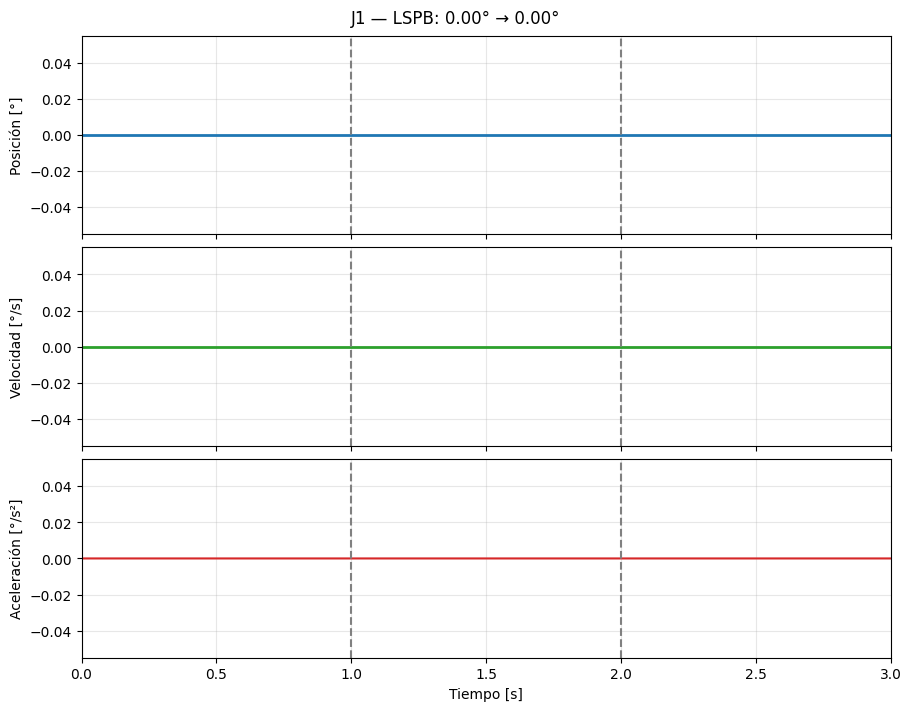

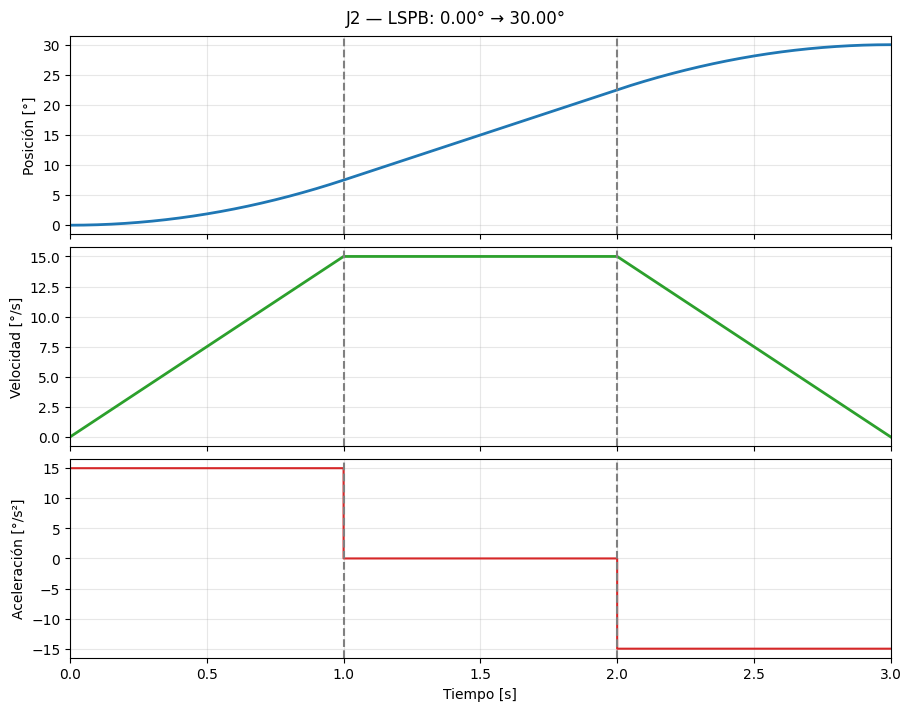

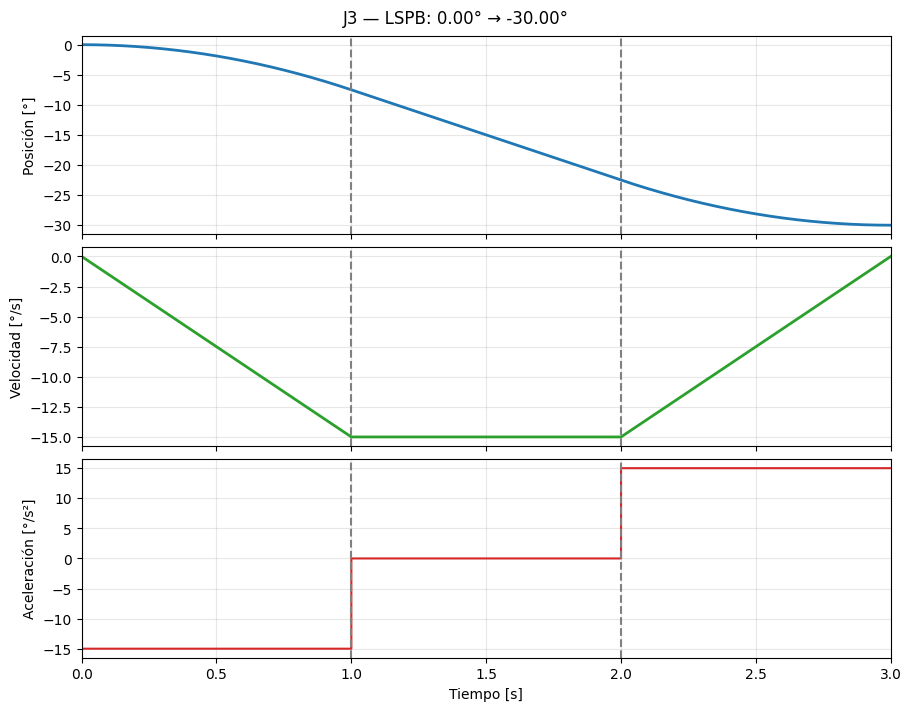

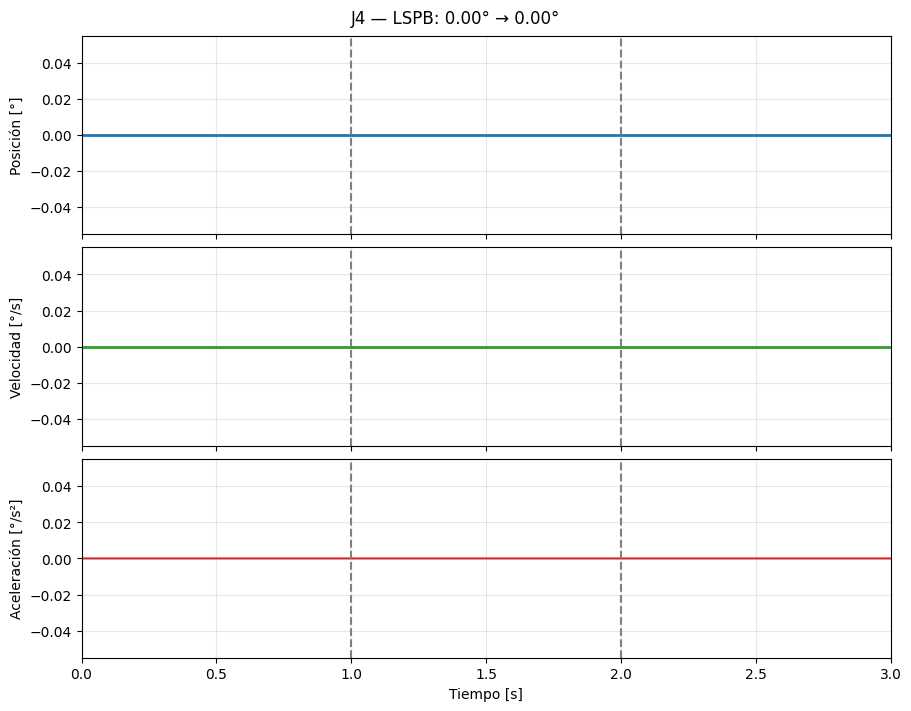

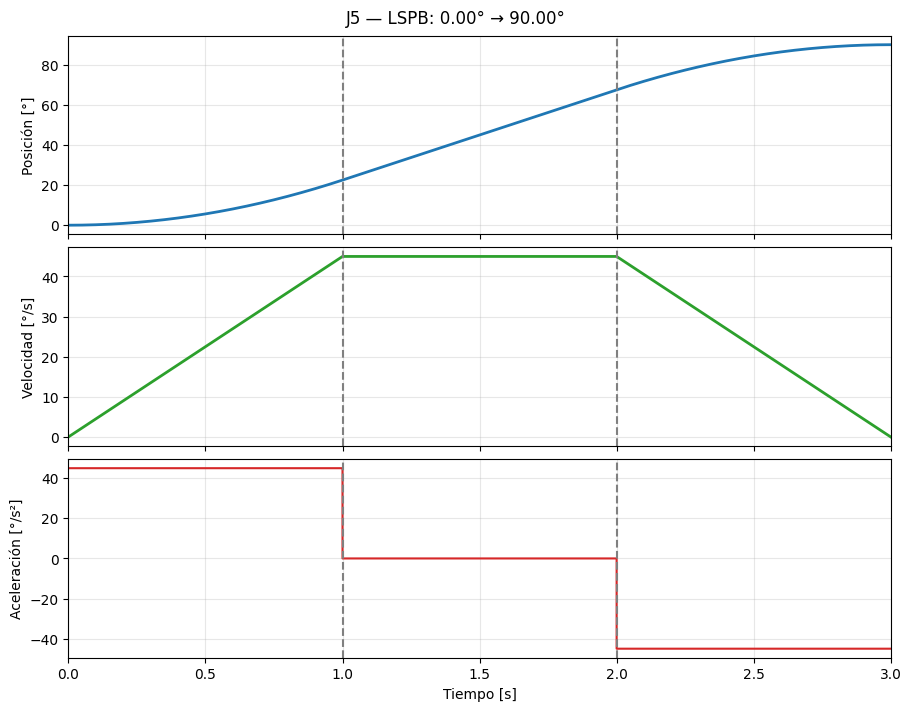

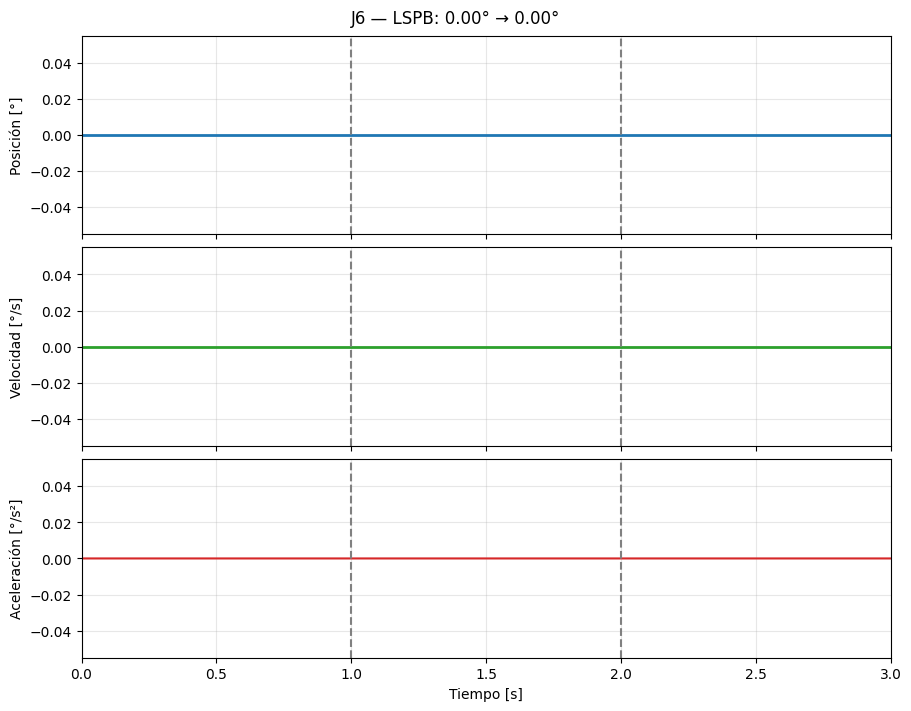

In [15]:
if trayectoria is None:
    raise ValueError("Primero genera y verifica la trayectoria.")

datos_graficas = [
    np.rad2deg(q),
    np.rad2deg(qd),
    np.rad2deg(qdd),
]

etiquetas = [
    "Posición [°]",
    "Velocidad [°/s]",
    "Aceleración [°/s²]",
]

colores = ["tab:blue", "tab:green", "tab:red"]

for j in range(6):
    fig, ejes = plt.subplots(
        3, 1,
        figsize=(9, 7),
        sharex=True,
        constrained_layout=True,
    )

    fig.suptitle(
        f"J{j+1} — LSPB: "
        f"{np.rad2deg(q_inicial[j]):.2f}° → "
        f"{np.rad2deg(q_final[j]):.2f}°"
    )

    for fila, ax in enumerate(ejes):
        # Limpiar residuos solo en la representación gráfica.
        valores = datos_graficas[fila][:, j].copy()
        valores[np.abs(valores) < 1e-10] = 0.0

        if fila == 2:
            ax.step(t, valores, where="post", color=colores[fila])
        else:
            ax.plot(t, valores, color=colores[fila], linewidth=2)

        ax.axvline(
            trayectoria["tc"], color="gray", linestyle="--"
        )
        ax.axvline(
            TIEMPO_TOTAL - trayectoria["tc"],
            color="gray", linestyle="--"
        )

        ax.set_ylabel(etiquetas[fila])
        ax.set_xlim(0, TIEMPO_TOTAL)
        ax.grid(True, alpha=0.3)

    ejes[-1].set_xlabel("Tiempo [s]")
    plt.show()
    plt.close(fig)

## 7. Jacobiano geométrico del TCP

El Jacobiano relaciona las velocidades articulares con las velocidades
lineal y angular del TCP, expresadas en la base:

$$
\begin{bmatrix}
v_{TCP}\\
\omega_{TCP}
\end{bmatrix}
=J(q)\dot q.
$$

Para cada articulación revoluta:

$$
J_j=
\begin{bmatrix}
{}^0z_{j-1}\times({}^0p_{TCP}-{}^0o_{j-1})\\
{}^0z_{j-1}
\end{bmatrix}.
$$

El Jacobiano tiene dimensión 6x6:
- Filas 1 a 3: velocidad lineal.
- Filas 4 a 6: velocidad angular.
- Cada columna corresponde a una articulación.

La velocidad angular no es, en general, el vector de derivadas
de los ángulos de Euler.

Se validará el Jacobiano mediante diferencias centrales de la
cinemática directa, incluyendo posición y orientación.

### 7.1. Construcción del Jacobiano a partir de la cinemática directa

El Jacobiano geométrico relaciona las velocidades articulares con la
velocidad lineal y angular del TCP:

$$
\begin{bmatrix}
{}^0v_{TCP}\\
{}^0\omega_{TCP}
\end{bmatrix}
=
J(q)\dot q.
$$

Todos los vectores se expresan respecto al sistema de coordenadas de la
base. Las velocidades articulares se utilizan en rad/s, por lo que se
obtienen velocidades lineales en m/s y angulares en rad/s.

Para una articulación revoluta, la columna correspondiente es:

$$
J_i=
\begin{bmatrix}
{}^0z_{i-1}\times
\left({}^0p_{TCP}-{}^0o_{i-1}\right)\\
{}^0z_{i-1}
\end{bmatrix}.
$$

Aquí:

- ${}^0z_{i-1}$ es el vector unitario del eje de giro de la junta $i$.
- ${}^0o_{i-1}$ es la posición del origen del marco anterior.
- ${}^0p_{TCP}$ es la posición del TCP.
- $\times$ representa el producto cruz.

Se utiliza el índice $i-1$ porque, en la convención D-H estándar,
la articulación $i$ gira alrededor de $z_{i-1}$.

#### Obtención de los ejes y los orígenes

Las transformaciones acumuladas se calculan mediante:

$$
{}^0T_0=I,
\qquad
{}^0T_i=A_1A_2\cdots A_i.
$$

Cada transformación tiene la estructura:

$$
{}^0T_i=
\begin{bmatrix}
r_{11}&r_{12}&r_{13}&p_x\\
r_{21}&r_{22}&r_{23}&p_y\\
r_{31}&r_{32}&r_{33}&p_z\\
0&0&0&1
\end{bmatrix}.
$$

Las columnas de su matriz de rotación representan las direcciones de los
ejes del marco $i$, expresadas en la base. Por tanto:

$$
{}^0z_i=
\begin{bmatrix}
r_{13}\\r_{23}\\r_{33}
\end{bmatrix},
\qquad
{}^0o_i=
\begin{bmatrix}
p_x\\p_y\\p_z
\end{bmatrix}.
$$

El eje se extrae de la tercera columna y el origen de la cuarta,
tomando únicamente las primeras tres filas.

Es necesario usar las matrices acumuladas ${}^0T_i$, no las matrices
individuales $A_i$, para que todos los vectores estén expresados
en la misma base.

| Columna | Eje utilizado | Origen utilizado | Transformación |
|---|---|---|---|
| $J_1$ | ${}^0z_0$ | ${}^0o_0$ | ${}^0T_0$ |
| $J_2$ | ${}^0z_1$ | ${}^0o_1$ | ${}^0T_1$ |
| $J_3$ | ${}^0z_2$ | ${}^0o_2$ | ${}^0T_2$ |
| $J_4$ | ${}^0z_3$ | ${}^0o_3$ | ${}^0T_3$ |
| $J_5$ | ${}^0z_4$ | ${}^0o_4$ | ${}^0T_4$ |
| $J_6$ | ${}^0z_5$ | ${}^0o_5$ | ${}^0T_5$ |

La posición del TCP se obtiene de la última columna de:

$$
{}^0T_{TCP}={}^0T_6\,{}^6T_{TCP}.
$$

La herramienta está unida mediante una transformación fija:
modifica la posición del punto de interés, pero no añade una articulación.
Por ello, el Jacobiano sigue teniendo seis columnas.

#### Justificación del producto cruz

La velocidad lineal producida por una rotación cumple:

$$
v=\omega\times r.
$$

Para la contribución de la junta $i$:

$$
\omega_i={}^0z_{i-1}\dot q_i,
\qquad
r_i={}^0p_{TCP}-{}^0o_{i-1}.
$$

Sustituyendo:

$$
v_i=
\left[
{}^0z_{i-1}\times
\left({}^0p_{TCP}-{}^0o_{i-1}\right)
\right]\dot q_i.
$$

El término entre corchetes forma la parte lineal de la columna.
La parte angular es directamente ${}^0z_{i-1}$.
Al reunir las contribuciones de las seis juntas:

$$
J(q)=
\begin{bmatrix}
J_1&J_2&J_3&J_4&J_5&J_6
\end{bmatrix}.
$$

In [16]:
def jacobiano_tcp(q_articular):
    """
    Jacobiano geométrico 6x6 del TCP, expresado en la base.

    Entrada:
        q_articular: seis ángulos [rad].

    Salida:
        J, con velocidad lineal arriba y angular abajo.
    """
    transformaciones = transformaciones_acumuladas(q_articular)

    T_TCP = transformaciones[-1] @ T_6_TCP
    p_TCP = T_TCP[:3, 3]

    J = np.zeros((6, 6))

    for j in range(6):
        # j=0 utiliza T_00; j=1 utiliza T_01; etc.
        T_anterior = transformaciones[j]

        origen = T_anterior[:3, 3]
        eje_z = T_anterior[:3, 2]

        J[:3, j] = np.cross(eje_z, p_TCP - origen)
        J[3:, j] = eje_z

    return J


print("Función del Jacobiano del TCP definida.")

Función del Jacobiano del TCP definida.


In [17]:
if q_final is None:
    raise ValueError("Primero debes seleccionar una configuración final.")

J_final = jacobiano_tcp(q_final)

print("Configuración final [grados]:")
print(np.round(np.rad2deg(q_final), 6))

print("\nJacobiano del TCP en la configuración final:")
print(J_final)

Configuración final [grados]:
[  0.  30. -30.   0.  90.   0.]

Jacobiano del TCP en la configuración final:
[[-0.        0.136827 -0.097    -0.       -0.167     0.      ]
 [ 0.437     0.        0.        0.167     0.       -0.      ]
 [ 0.       -0.437    -0.302     0.        0.       -0.      ]
 [ 0.        0.        0.        1.        0.       -0.      ]
 [ 0.        1.        1.        0.        1.        0.      ]
 [ 1.        0.        0.       -0.        0.       -1.      ]]


### 7.2. Desarrollo manual en la configuración final del caso de estudio

Se considera la configuración:

$$
q_f=
\begin{bmatrix}
0&30&-30&0&90&0
\end{bmatrix}^{T}
\;[^\circ].
$$

En la tabla D-H, la segunda articulación incorpora el desfase:

$$
\theta_2=q_2-90^\circ=-60^\circ.
$$

Los cálculos siguientes corresponden exclusivamente a esta configuración.

#### Ejes y orígenes obtenidos de las transformaciones acumuladas

Al evaluar las matrices D-H y multiplicarlas desde la base, se obtienen:

| Marco $i$ | ${}^0z_i$ | ${}^0o_i$ [m] |
|---|---|---|
| 0 | $(0,0,1)^T$ | $(0,0,0)^T$ |
| 1 | $(0,1,0)^T$ | $(0,0,0.290)^T$ |
| 2 | $(0,1,0)^T$ | $(0.135,0,0.523826859)^T$ |
| 3 | $(1,0,0)^T$ | $(0.135,0,0.593826859)^T$ |
| 4 | $(0,1,0)^T$ | $(0.437,0,0.593826859)^T$ |
| 5 | $(0,0,-1)^T$ | $(0.437,0,0.593826859)^T$ |

Por ejemplo:

$$
{}^0T_2=
\begin{bmatrix}
0.5&0.8660254&0&0.135\\
0&0&1&0\\
0.8660254&-0.5&0&0.523826859\\
0&0&0&1
\end{bmatrix}.
$$

De su tercera y cuarta columnas se extraen:

$$
{}^0z_2=
\begin{bmatrix}0\\1\\0\end{bmatrix},
\qquad
{}^0o_2=
\begin{bmatrix}0.135\\0\\0.523826859\end{bmatrix}.
$$

Estos datos se utilizan para construir la columna de la junta 3.

#### Posición del TCP

La posición del origen del marco 6 es:

$$
{}^0o_6=
\begin{bmatrix}
0.437\\0\\0.521826859
\end{bmatrix}\;\mathrm{m}.
$$

La herramienta del modelo añade $0.095$ m sobre $+z_6$.
En esta configuración, dicho eje apunta hacia $-Z$ de la base:

$$
{}^0z_6=
\begin{bmatrix}0\\0\\-1\end{bmatrix}.
$$

Por tanto:

$$
{}^0p_{TCP}
={}^0o_6+0.095\,{}^0z_6
=
\begin{bmatrix}
0.437\\0\\0.426826859
\end{bmatrix}\;\mathrm{m}.
$$

Esta misma posición se utiliza en las seis columnas.

#### Cálculo de las partes lineales

En las expresiones siguientes se omite el superíndice $0$;
todos los vectores continúan expresados en la base.

Para la junta 1:

$$
J_{v,1}
=z_0\times(p_{TCP}-o_0)
=
\begin{bmatrix}0\\0\\1\end{bmatrix}
\times
\begin{bmatrix}0.437\\0\\0.426826859\end{bmatrix}
=
\begin{bmatrix}0\\0.437\\0\end{bmatrix}.
$$

Para la junta 2:

$$
J_{v,2}
=z_1\times(p_{TCP}-o_1)
=
\begin{bmatrix}0\\1\\0\end{bmatrix}
\times
\begin{bmatrix}0.437\\0\\0.136826859\end{bmatrix}
=
\begin{bmatrix}0.136826859\\0\\-0.437\end{bmatrix}.
$$

Para la junta 3:

$$
J_{v,3}
=z_2\times(p_{TCP}-o_2)
=
\begin{bmatrix}0\\1\\0\end{bmatrix}
\times
\begin{bmatrix}0.302\\0\\-0.097\end{bmatrix}
=
\begin{bmatrix}-0.097\\0\\-0.302\end{bmatrix}.
$$

Para la junta 4:

$$
J_{v,4}
=z_3\times(p_{TCP}-o_3)
=
\begin{bmatrix}1\\0\\0\end{bmatrix}
\times
\begin{bmatrix}0.302\\0\\-0.167\end{bmatrix}
=
\begin{bmatrix}0\\0.167\\0\end{bmatrix}.
$$

Para la junta 5:

$$
J_{v,5}
=z_4\times(p_{TCP}-o_4)
=
\begin{bmatrix}0\\1\\0\end{bmatrix}
\times
\begin{bmatrix}0\\0\\-0.167\end{bmatrix}
=
\begin{bmatrix}-0.167\\0\\0\end{bmatrix}.
$$

Para la junta 6:

$$
J_{v,6}
=z_5\times(p_{TCP}-o_5)
=
\begin{bmatrix}0\\0\\-1\end{bmatrix}
\times
\begin{bmatrix}0\\0\\-0.167\end{bmatrix}
=
\begin{bmatrix}0\\0\\0\end{bmatrix}.
$$

La parte lineal de la sexta columna es cero porque el TCP se encuentra
sobre el eje de giro de esa articulación. La junta 6 modifica la
orientación, pero no la posición de este TCP.

#### Ensamblaje del Jacobiano

Debajo de cada producto cruz se coloca el eje de giro correspondiente:

$$
J_{\omega}=
\begin{bmatrix}
z_0&z_1&z_2&z_3&z_4&z_5
\end{bmatrix}.
$$

El resultado es:

$$
\boxed{
J(q_f)=
\begin{bmatrix}
0&0.136826859&-0.097&0&-0.167&0\\
0.437&0&0&0.167&0&0\\
0&-0.437&-0.302&0&0&0\\
0&0&0&1&0&0\\
0&1&1&0&1&0\\
1&0&0&0&0&-1
\end{bmatrix}.
}
$$

Los valores están redondeados. La matriz calculada por el código debe
coincidir con este resultado dentro del error de redondeo.

Esta es una evaluación del Jacobiano geométrico en $q_f$.
Durante la trayectoria se debe recalcular $J(q(t))$ en cada instante;
no se utiliza una matriz final constante para todo el movimiento.

In [18]:
def jacobiano_por_diferencias(q_articular, epsilon=1e-6):
    """Aproximación numérica del Jacobiano a partir de la FK."""
    q_articular = np.asarray(q_articular, dtype=float)

    R_actual = cinematica_tcp(q_articular)[:3, :3]
    J_numerico = np.zeros((6, 6))

    for j in range(6):
        incremento = np.zeros(6)
        incremento[j] = epsilon

        T_mas = cinematica_tcp(q_articular + incremento)
        T_menos = cinematica_tcp(q_articular - incremento)

        # Derivada de la posición respecto a q_j.
        J_numerico[:3, j] = (
            T_mas[:3, 3] - T_menos[:3, 3]
        ) / (2.0 * epsilon)

        # Derivada de la rotación respecto a q_j.
        derivada_R = (
            T_mas[:3, :3] - T_menos[:3, :3]
        ) / (2.0 * epsilon)

        matriz_angular = derivada_R @ R_actual.T

        # Eliminar la pequeña parte simétrica del error numérico.
        matriz_angular = 0.5 * (
            matriz_angular - matriz_angular.T
        )

        J_numerico[3:, j] = [
            matriz_angular[2, 1],
            matriz_angular[0, 2],
            matriz_angular[1, 0],
        ]

    return J_numerico


J_numerico = jacobiano_por_diferencias(q_final)

error_lineal = np.max(np.abs(
    J_final[:3, :] - J_numerico[:3, :]
))

error_angular = np.max(np.abs(
    J_final[3:, :] - J_numerico[3:, :]
))

print("Máxima diferencia en bloque lineal:", error_lineal)
print("Máxima diferencia en bloque angular:", error_angular)

if error_lineal > 1e-7 or error_angular > 1e-7:
    raise ValueError("El Jacobiano no coincide con la derivada numérica de FK.")

print("\nOK — Jacobiano geométrico consistente con la cinemática directa.")

Máxima diferencia en bloque lineal: 7.529377121784364e-11
Máxima diferencia en bloque angular: 1.3284084943165908e-10

OK — Jacobiano geométrico consistente con la cinemática directa.


In [19]:
J_trayectoria = None
velocidad_tcp = None

if trayectoria is None:
    raise ValueError("Primero debes generar la trayectoria LSPB.")

# Una matriz 6x6 por instante.
J_trayectoria = np.array([
    jacobiano_tcp(q_instante)
    for q_instante in q
])

# Un vector de seis velocidades por instante.
velocidad_tcp = np.array([
    J_instante @ qd_instante
    for J_instante, qd_instante in zip(J_trayectoria, qd)
])

v_tcp = velocidad_tcp[:, :3]       # [m/s]
omega_tcp = velocidad_tcp[:, 3:]   # [rad/s]

print("Dimensiones de J_trayectoria:", J_trayectoria.shape)
print("Dimensiones de velocidad_tcp:", velocidad_tcp.shape)

print("\nVelocidad del TCP al inicio:")
print(velocidad_tcp[0])

print("\nVelocidad del TCP al final:")
print(velocidad_tcp[-1])

if not np.allclose(
    velocidad_tcp[[0, -1]], 0.0, atol=1e-10, rtol=0
):
    raise ValueError("El TCP no está en reposo en las fronteras.")

print("\nOK — El TCP comienza y termina en reposo.")

Dimensiones de J_trayectoria: (601, 6, 6)
Dimensiones de velocidad_tcp: (601, 6)

Velocidad del TCP al inicio:
[0. 0. 0. 0. 0. 0.]

Velocidad del TCP al final:
[0. 0. 0. 0. 0. 0.]

OK — El TCP comienza y termina en reposo.


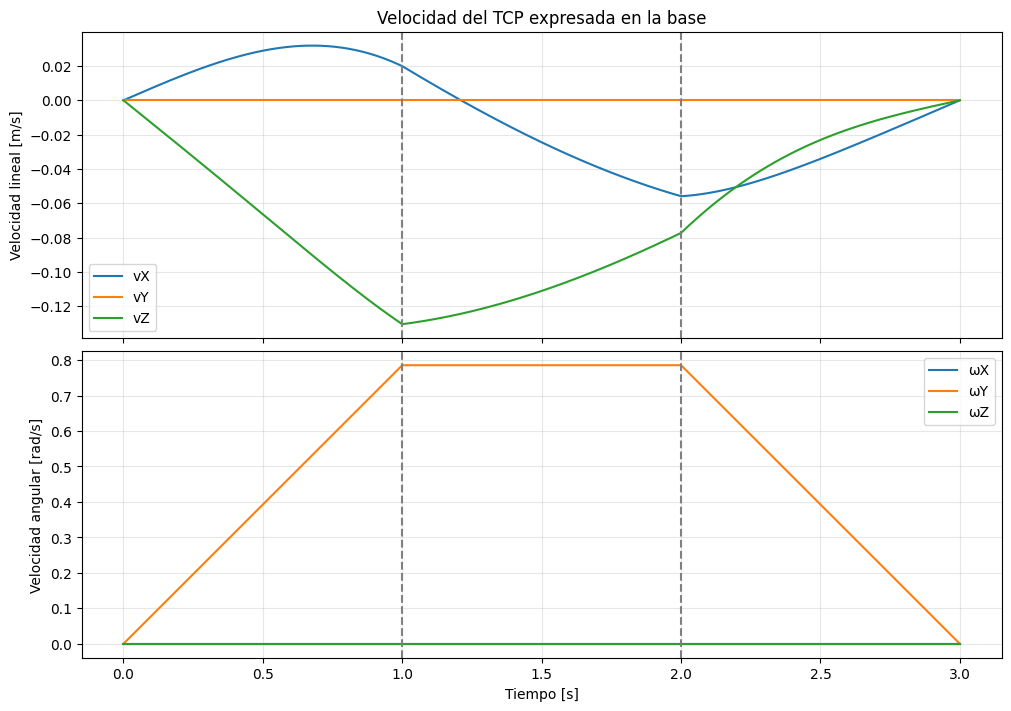

In [20]:
fig, ejes = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True,
    constrained_layout=True,
)

for componente, nombre in enumerate(["X", "Y", "Z"]):
    ejes[0].plot(
        t, v_tcp[:, componente],
        label=f"v{nombre}",
    )

    ejes[1].plot(
        t, omega_tcp[:, componente],
        label=f"ω{nombre}",
    )

ejes[0].set_title("Velocidad del TCP expresada en la base")
ejes[0].set_ylabel("Velocidad lineal [m/s]")
ejes[1].set_ylabel("Velocidad angular [rad/s]")
ejes[1].set_xlabel("Tiempo [s]")

for ax in ejes:
    ax.axvline(trayectoria["tc"], color="gray", linestyle="--")
    ax.axvline(
        TIEMPO_TOTAL - trayectoria["tc"],
        color="gray", linestyle="--"
    )
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.show()
plt.close(fig)

### 7.3. Interpretación de las velocidades del TCP

Para el caso de estudio, el movimiento parte de:

$$
q_i=
\begin{bmatrix}
0&0&0&0&0&0
\end{bmatrix}^{T}
$$

y termina en:

$$
q_f=
\begin{bmatrix}
0&30&-30&0&90&0
\end{bmatrix}^{T}
\;[^\circ].
$$

Como las articulaciones utilizan el mismo perfil temporal normalizado
del LSPB, se conservan las relaciones:

$$
q_3(t)=-q_2(t),
\qquad
q_5(t)=3q_2(t),
\qquad
q_1(t)=q_4(t)=q_6(t)=0.
$$

Definiendo $\theta(t)=q_2(t)$ en radianes:

$$
q(t)=
\begin{bmatrix}
0&\theta&-\theta&0&3\theta&0
\end{bmatrix}^{T},
$$

$$
\dot q(t)=
\begin{bmatrix}
0&\dot\theta&-\dot\theta&0&3\dot\theta&0
\end{bmatrix}^{T}.
$$

Por ello, la velocidad del TCP se obtiene mediante:

$$
\begin{bmatrix}
v_{TCP}\\
\omega_{TCP}
\end{bmatrix}
=
\left[J_2(q(t))-J_3(q(t))+3J_5(q(t))\right]\dot\theta.
$$

Las columnas correspondientes a juntas detenidas siguen formando parte
del Jacobiano, pero su contribución a la velocidad es cero.

#### Comprobación mediante la posición del TCP

Definimos la distancia desde el centro de muñeca hasta el TCP:

$$
\ell=d_6+L_{TCP}=0.072+0.095=0.167\;\mathrm{m}.
$$

Al sustituir las relaciones articulares anteriores en la cinemática
directa, la posición se reduce a:

$$
x(t)=a_2\sin\theta+d_4+\ell\cos(3\theta),
$$

$$
y(t)=0,
$$

$$
z(t)=d_1+a_2\cos\theta+a_3-\ell\sin(3\theta).
$$

Derivando respecto al tiempo y aplicando la regla de la cadena:

$$
v_x(t)=
\left[a_2\cos\theta-3\ell\sin(3\theta)\right]\dot\theta,
$$

$$
v_y(t)=0,
$$

$$
v_z(t)=
\left[-a_2\sin\theta-3\ell\cos(3\theta)\right]\dot\theta.
$$

El factor 3 aparece porque:

$$
\frac{d(3\theta)}{dt}=3\dot\theta.
$$

Para la velocidad angular, en este movimiento los ejes de las juntas
2, 3 y 5 apuntan hacia $+Y$ de la base. Sus contribuciones son:

$$
\omega_{TCP}
=
\begin{bmatrix}0\\1\\0\end{bmatrix}\dot\theta
+
\begin{bmatrix}0\\1\\0\end{bmatrix}(-\dot\theta)
+
\begin{bmatrix}0\\1\\0\end{bmatrix}(3\dot\theta).
$$

Por tanto:

$$
\boxed{
\omega_{TCP}(t)=
\begin{bmatrix}
0\\3\dot\theta\\0
\end{bmatrix}.
}
$$

Estas expresiones permiten interpretar las gráficas:

- $v_y=0$: el TCP permanece en el plano $XZ$ de la base.
- $\omega_x=\omega_z=0$: la velocidad angular apunta sobre el eje $Y$.
- $v_x$ y $v_z$ dependen tanto de la postura como de la velocidad articular.
- Una velocidad articular constante durante el crucero no implica
  componentes constantes de velocidad lineal del TCP.

Las componentes teóricamente nulas pueden presentar residuos pequeños
por redondeo numérico.

#### Condiciones de inicio y fin

El perfil LSPB impone:

$$
\dot q(0)=\dot q(t_f)=0.
$$

En consecuencia:

$$
v_{TCP}(0)=v_{TCP}(t_f)=0,
$$

$$
\omega_{TCP}(0)=\omega_{TCP}(t_f)=0.
$$

El reposo final se debe a que las velocidades articulares son cero,
no a que el Jacobiano sea una matriz nula.

Estas relaciones simplificadas corresponden a esta trayectoria y a
esta rama de solución. Para otras poses o configuraciones se utiliza
la expresión general $[v_{TCP}^{T},\omega_{TCP}^{T}]^{T}=J(q)\dot q$.

## 8. Singularidades y pérdida de movilidad

Una configuración es singular cuando el Jacobiano del TCP pierde
rango respecto a su máximo de 6.

Se analizarán:
1. Las configuraciones de la trayectoria LSPB.
2. Un experimento independiente de aproximación a q5 = 0.

Para nuestro modelo, cuando q5 = 0, los ejes de J4 y J6 se alinean
y sus columnas del Jacobiano coinciden.

Para estudiar la proximidad a singularidad se utiliza:

$$
\bar J =
\begin{bmatrix}
J_v/L_{\mathrm{ref}}\\
J_\omega
\end{bmatrix},
\qquad L_{\mathrm{ref}}=a_2.
$$

Se registran el rango numérico y el menor valor singular.

El rango se calcula contando los valores singulares que superan
una tolerancia relativa de 1e-9 respecto al mayor.

Una singularidad no implica inmovilidad completa ni torque infinito.

In [21]:
LONGITUD_REFERENCIA = A2
TOL_RANGO_RELATIVA = 1e-9


def diagnostico_jacobiano(J):
    """Diagnóstico con escalamiento explícito del bloque lineal."""
    J_escalado = np.asarray(J, dtype=float).copy()
    J_escalado[:3, :] /= LONGITUD_REFERENCIA

    valores = np.linalg.svd(J_escalado, compute_uv=False)

    umbral = TOL_RANGO_RELATIVA * valores[0]
    rango = int(np.count_nonzero(valores > umbral))

    return {
        "rango": rango,
        "sigma_min": float(valores[-1]),
        "sigma_max": float(valores[0]),
        "umbral": float(umbral),
    }


print("Función de diagnóstico definida.")

Función de diagnóstico definida.


In [22]:
if J_trayectoria is None:
    raise ValueError("Primero debes calcular el Jacobiano de la trayectoria.")

diagnosticos_trayectoria = [
    diagnostico_jacobiano(J_instante)
    for J_instante in J_trayectoria
]

rangos_trayectoria = np.array([
    dato["rango"]
    for dato in diagnosticos_trayectoria
])

sigma_min_trayectoria = np.array([
    dato["sigma_min"]
    for dato in diagnosticos_trayectoria
])

indices_singulares = np.flatnonzero(rangos_trayectoria < 6)

print("Rango inicial:", rangos_trayectoria[0])
print("Rango final:", rangos_trayectoria[-1])
print("Mínimo rango registrado:", np.min(rangos_trayectoria))

print(
    "Muestras clasificadas como singulares:",
    len(indices_singulares),
    "de",
    len(t),
)

if len(indices_singulares):
    print(
        "Primeros tiempos clasificados como singulares [s]:",
        t[indices_singulares[:10]],
    )

Rango inicial: 5
Rango final: 6
Mínimo rango registrado: 5
Muestras clasificadas como singulares: 1 de 601
Primeros tiempos clasificados como singulares [s]: [0.]


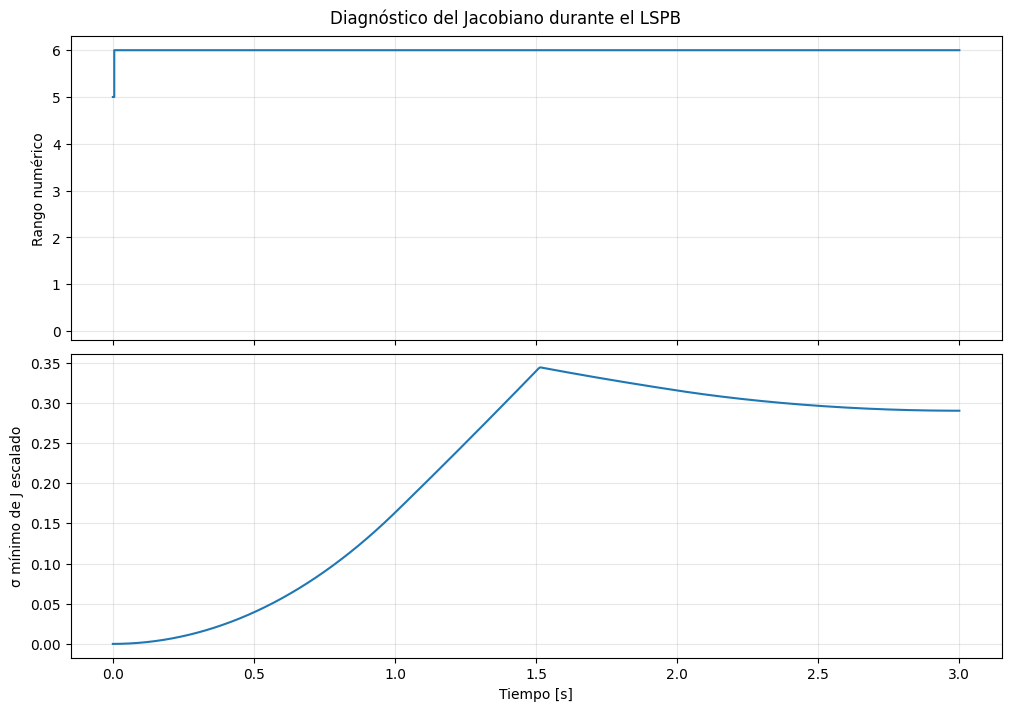

In [23]:
fig, ejes = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True,
    constrained_layout=True,
)

ejes[0].step(t, rangos_trayectoria, where="post")
ejes[0].set_ylabel("Rango numérico")
ejes[0].set_yticks(range(7))
ejes[0].set_ylim(-0.2, 6.3)

ejes[1].plot(t, sigma_min_trayectoria)
ejes[1].set_ylabel("σ mínimo de J escalado")
ejes[1].set_xlabel("Tiempo [s]")

for ax in ejes:
    ax.grid(True, alpha=0.3)

fig.suptitle("Diagnóstico del Jacobiano durante el LSPB")
plt.show()
plt.close(fig)

In [24]:
angulos_experimento_deg = np.array([
    30.0, 10.0, 5.0, 1.0, 0.5, 0.1, 0.05, 0.01, 0.0
])

# Secuencia independiente; no reemplaza la trayectoria principal.
configuraciones_experimento = np.tile(
    np.deg2rad([0, 30, -30, 0, 0, 0]),
    (len(angulos_experimento_deg), 1),
)

configuraciones_experimento[:, 4] = np.deg2rad(
    angulos_experimento_deg
)

if not np.all(
    (configuraciones_experimento >= Q_MIN)
    & (configuraciones_experimento <= Q_MAX)
):
    raise ValueError("El experimento contiene ángulos fuera de límites.")

velocidad_deseada_experimento = np.array([
    0.0, 0.0, 0.0,    # Velocidad lineal [m/s].
    0.0, 0.0, 0.1,    # Velocidad angular [rad/s].
])

registro_singularidad = []

for angulo, configuracion in zip(
    angulos_experimento_deg,
    configuraciones_experimento,
):
    J_exp = jacobiano_tcp(configuracion)
    diagnostico = diagnostico_jacobiano(J_exp)

    qd_requerida = None
    norma_qd = np.nan

    if diagnostico["rango"] == 6:
        # Resolver el sistema sin formar explícitamente J^-1.
        qd_requerida = np.linalg.solve(
            J_exp,
            velocidad_deseada_experimento,
        )

        velocidad_recuperada = J_exp @ qd_requerida

        if not np.allclose(
            velocidad_recuperada,
            velocidad_deseada_experimento,
            atol=1e-8,
            rtol=0,
        ):
            raise ValueError("No se recuperó la velocidad cartesiana deseada.")

        norma_qd = np.linalg.norm(qd_requerida)

    registro_singularidad.append({
        "q5_deg": float(angulo),
        "rango": diagnostico["rango"],
        "sigma_min": diagnostico["sigma_min"],
        "norma_qd": float(norma_qd),
        "qd_requerida": qd_requerida,
    })


print(
    f"{'q5 [°]':>10}"
    f"{'Rango':>9}"
    f"{'σ mínimo':>16}"
    f"{'||qd|| [rad/s]':>20}"
)
print("-" * 55)

for fila in registro_singularidad:
    texto_velocidad = (
        f"{fila['norma_qd']:.6f}"
        if np.isfinite(fila["norma_qd"])
        else "No se invierte"
    )

    print(
        f"{fila['q5_deg']:>10.4f}"
        f"{fila['rango']:>9d}"
        f"{fila['sigma_min']:>16.6e}"
        f"{texto_velocidad:>20}"
    )

    q5 [°]    Rango        σ mínimo      ||qd|| [rad/s]
-------------------------------------------------------
   30.0000        6    2.438257e-01            0.353689
   10.0000        6    8.149051e-02            1.113068
    5.0000        6    4.075515e-02            2.236423
    1.0000        6    8.151663e-03           11.198667
    0.5000        6    4.075841e-03           22.398371
    0.1000        6    8.151689e-04          111.993512
    0.0500        6    4.075844e-04          223.987128
    0.0100        6    8.151689e-05         1119.935804
    0.0000        5    7.706722e-17      No se invierte


In [25]:
q_singular_experimento = configuraciones_experimento[-1]
J_singular_experimento = jacobiano_tcp(q_singular_experimento)

print("Columnas de J4 y J6:")
print(J_singular_experimento[:, [3, 5]])

print("\nDiferencia entre las columnas:")
print(
    J_singular_experimento[:, 3]
    - J_singular_experimento[:, 5]
)

# Restricción: vy - 0.604*wz = 0.
restriccion = np.array([0.0, 1.0, 0.0, 0.0, 0.0, -0.604])

print("\nRestricción aplicada al Jacobiano:")
print(restriccion @ J_singular_experimento)

print("\nRestricción aplicada a la velocidad solicitada:")
print(restriccion @ velocidad_deseada_experimento)

Columnas de J4 y J6:
[[-0. -0.]
 [ 0.  0.]
 [ 0.  0.]
 [ 1.  1.]
 [ 0.  0.]
 [ 0.  0.]]

Diferencia entre las columnas:
[-0.  0.  0.  0.  0.  0.]

Restricción aplicada al Jacobiano:
[-0. -0. -0. -0. -0. -0.]

Restricción aplicada a la velocidad solicitada:
-0.0604


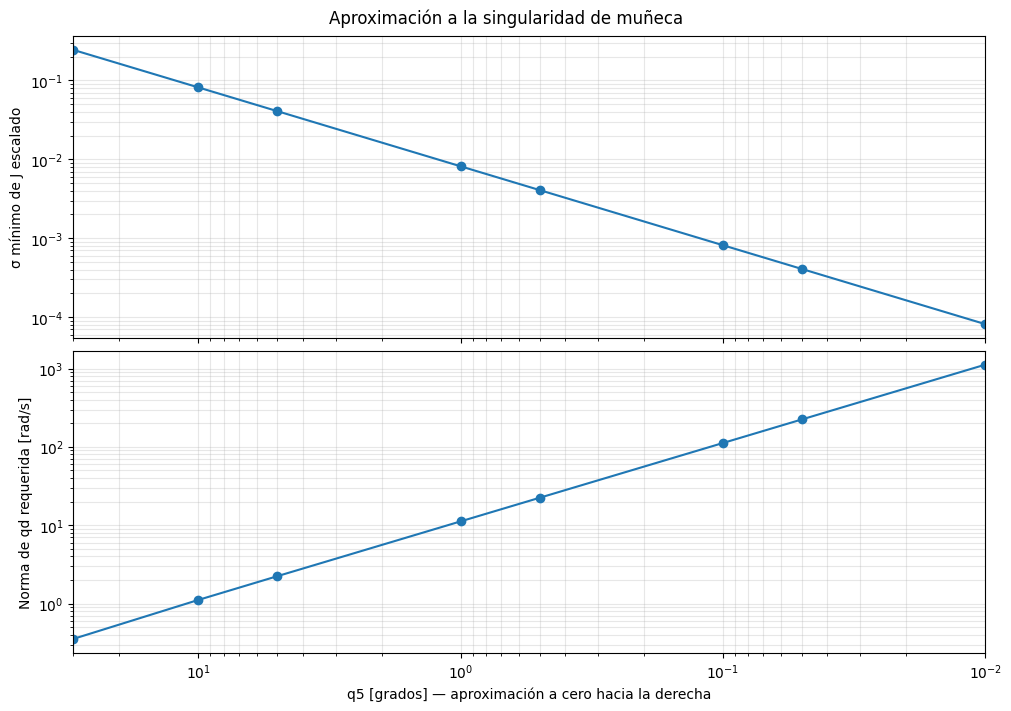

In [26]:
angulos_positivos = np.array([
    fila["q5_deg"]
    for fila in registro_singularidad
    if fila["q5_deg"] > 0
])

sigma_positivos = np.array([
    fila["sigma_min"]
    for fila in registro_singularidad
    if fila["q5_deg"] > 0
])

normas_velocidad = np.array([
    fila["norma_qd"]
    for fila in registro_singularidad
    if fila["q5_deg"] > 0
])

fig, ejes = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True,
    constrained_layout=True,
)

ejes[0].loglog(angulos_positivos, sigma_positivos, "o-")
ejes[0].set_ylabel("σ mínimo de J escalado")

ejes[1].loglog(angulos_positivos, normas_velocidad, "o-")
ejes[1].set_ylabel("Norma de qd requerida [rad/s]")
ejes[1].set_xlabel("q5 [grados] — aproximación a cero hacia la derecha")

# Orden visual: de mayor a menor ángulo.
ejes[1].set_xlim(
    np.max(angulos_positivos),
    np.min(angulos_positivos),
)

for ax in ejes:
    ax.grid(True, which="both", alpha=0.3)

fig.suptitle("Aproximación a la singularidad de muñeca")
plt.show()
plt.close(fig)

## 9. Dinámica reducida 1R

Se utiliza el modelo pedagógico de un eslabón que gira en un plano
vertical. El ángulo theta se mide desde la vertical hacia abajo.

Energías:

$$
E_c=\frac12 I_{\mathrm{eq}}\dot\theta^2
$$

$$
E_p=mg\ell_c(1-\cos\theta)
$$

Aplicando Euler–Lagrange:

$$
\tau=I_{\mathrm{eq}}\ddot\theta+mg\ell_c\sin\theta.
$$

Se aplica la trayectoria angular de J2 al modelo 1R:

$$
\theta(t)=q_2(t).
$$

Esta es una excitación del modelo pedagógico, no una identificación
dinámica del motor J2 del ABB.

Parámetros del ejemplo docente:
- I_eq = 0.25 kg·m²
- m = 1 kg
- lc = 0.5 m
- g = 9.81 m/s²

Se desprecia fricción. El término de Coriolis es cero en este
modelo de una articulación con inercia constante.

In [27]:
def dinamica_1r(theta, theta_dd, inercia, masa, lc, gravedad):
    """Torque del modelo pedagógico 1R, en N·m."""
    theta = np.asarray(theta, dtype=float)
    theta_dd = np.asarray(theta_dd, dtype=float)

    if theta.shape != theta_dd.shape:
        raise ValueError("Posición y aceleración deben tener la misma forma.")

    if not np.all(np.isfinite(theta)) or not np.all(np.isfinite(theta_dd)):
        raise ValueError("La trayectoria contiene valores no finitos.")

    parametros = np.array([inercia, masa, lc, gravedad], dtype=float)

    if not np.all(np.isfinite(parametros)) or np.any(parametros <= 0):
        raise ValueError("Los parámetros deben ser positivos y finitos.")

    tau_inercial = inercia * theta_dd
    tau_gravedad = masa * gravedad * lc * np.sin(theta)

    # Modelo ideal 1R con inercia constante, sin fricción.
    tau_velocidad = np.zeros_like(theta)

    tau_total = tau_inercial + tau_gravedad + tau_velocidad

    return {
        "inercial": tau_inercial,
        "gravedad": tau_gravedad,
        "velocidad": tau_velocidad,
        "total": tau_total,
    }

In [28]:
torques_1r = None

if trayectoria is None:
    raise ValueError("Primero genera la trayectoria LSPB.")

# Parámetros ilustrativos del material de clase.
INERCIA_1R = 0.25       # kg·m²
MASA_1R = 1.0          # kg
LC_1R = 0.5            # m
GRAVEDAD = 9.81        # m/s²

# Índice 1 corresponde a J2.
JUNTA_MODELO_1R = 1

theta_1r = trayectoria["q"][:, JUNTA_MODELO_1R].copy()
theta_d_1r = trayectoria["qd"][:, JUNTA_MODELO_1R].copy()
theta_dd_1r = trayectoria["qdd"][:, JUNTA_MODELO_1R].copy()

torques_1r = dinamica_1r(
    theta_1r,
    theta_dd_1r,
    INERCIA_1R,
    MASA_1R,
    LC_1R,
    GRAVEDAD,
)

indice_pico = np.argmax(np.abs(torques_1r["total"]))

print("Entrada del modelo pedagógico: trayectoria de J2.")
print("Ángulo inicial [°]:", np.rad2deg(theta_1r[0]))
print("Ángulo final [°]:", np.rad2deg(theta_1r[-1]))

print("\nMáximo |torque| entre las muestras del movimiento [N·m]:")
print(np.abs(torques_1r["total"][indice_pico]))

print("Instante de esa muestra [s]:")
print(t[indice_pico])

# Torque para mantener la postura final después de detenerse.
tau_sosten_final = (
    MASA_1R * GRAVEDAD * LC_1R * np.sin(theta_1r[-1])
)

print("\nTorque de sostén final, con aceleración cero [N·m]:")
print(tau_sosten_final)

Entrada del modelo pedagógico: trayectoria de J2.
Ángulo inicial [°]: 0.0
Ángulo final [°]: 30.000000000000018

Máximo |torque| entre las muestras del movimiento [N·m]:
2.3870501530502137
Instante de esa muestra [s]:
3.0

Torque de sostén final, con aceleración cero [N·m]:
2.452500000000001


In [29]:
theta_prueba = np.array([
    0.0,
    np.pi / 2,
    -np.pi / 2,
    0.0,
])

aceleracion_prueba = np.array([
    0.0,
    0.0,
    0.0,
    1.0,
])

prueba = dinamica_1r(
    theta_prueba,
    aceleracion_prueba,
    INERCIA_1R,
    MASA_1R,
    LC_1R,
    GRAVEDAD,
)

esperado = np.array([
    0.0,
    MASA_1R * GRAVEDAD * LC_1R,
    -MASA_1R * GRAVEDAD * LC_1R,
    INERCIA_1R,
])

if not np.allclose(prueba["total"], esperado, atol=1e-12, rtol=0):
    raise ValueError("El modelo no supera los casos de comprobación.")

print("OK — Vertical inferior en reposo: torque cero.")
print("OK — Horizontal positiva: torque +m*g*lc.")
print("OK — Horizontal negativa: torque -m*g*lc.")
print("OK — En theta=0 con aceleración 1 rad/s²: torque I_eq.")

OK — Vertical inferior en reposo: torque cero.
OK — Horizontal positiva: torque +m*g*lc.
OK — Horizontal negativa: torque -m*g*lc.
OK — En theta=0 con aceleración 1 rad/s²: torque I_eq.


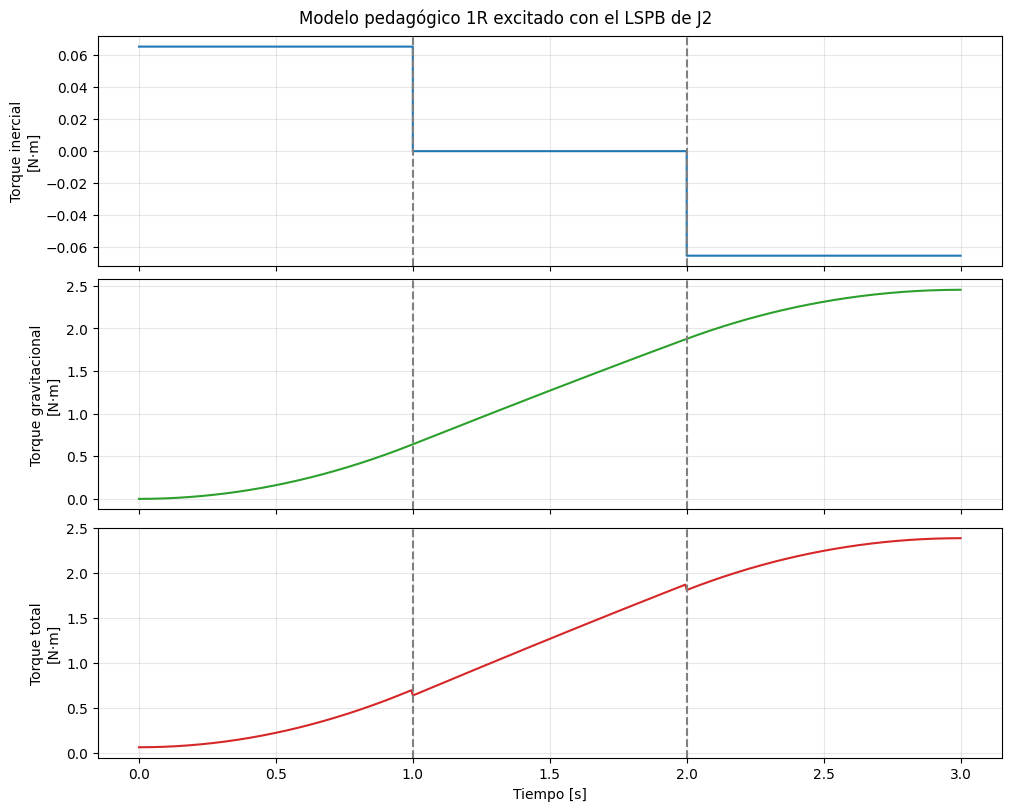

In [30]:
if torques_1r is None:
    raise ValueError("Primero debes calcular los torques.")

fig, ejes = plt.subplots(
    3, 1,
    figsize=(10, 8),
    sharex=True,
    constrained_layout=True,
)

ejes[0].step(
    t, torques_1r["inercial"],
    where="post", color="tab:blue",
)
ejes[0].set_ylabel("Torque inercial\n[N·m]")

ejes[1].plot(
    t, torques_1r["gravedad"],
    color="tab:green",
)
ejes[1].set_ylabel("Torque gravitacional\n[N·m]")

ejes[2].plot(
    t, torques_1r["total"],
    color="tab:red",
)
ejes[2].set_ylabel("Torque total\n[N·m]")
ejes[2].set_xlabel("Tiempo [s]")

for ax in ejes:
    ax.axvline(
        trayectoria["tc"],
        color="gray", linestyle="--",
    )
    ax.axvline(
        TIEMPO_TOTAL - trayectoria["tc"],
        color="gray", linestyle="--",
    )
    ax.grid(True, alpha=0.3)

fig.suptitle("Modelo pedagógico 1R excitado con el LSPB de J2")
plt.show()
plt.close(fig)

### Registro reproducible de varias poses
Cada caso vuelve a calcular IK, FK, LSPB, Jacobiano y dinámica ilustrativa 1R.
La entrada principal `T_d` no se modifica. Las poses generadas mediante FK sirven
como pruebas controladas con una configuración conocida; también se pueden añadir
matrices medidas o propuestas por el docente. La IK puede seleccionar otra rama válida.
El rango mínimo corresponde a las muestras, no a una certificación continua.
El estado `OK` significa cálculos verificados, no ausencia de singularidades.
El centro de muñeca sobre el eje de la base se trata mediante una familia
analítica y una partición de los intervalos permitidos de q1.


In [31]:
def evaluar_caso(T_objetivo, qi):
    registros, candidatos, singulares = resolver_ik_completa(T_objetivo, qi)
    if not candidatos:
        raise ValueError("Sin solución admisible dentro de los límites del modelo.")
    elegido = min(candidatos, key=lambda c: np.linalg.norm(c["q"]-qi))
    qf = elegido["q"]
    tray = generar_lspb(qi, qf, TIEMPO_TOTAL, FACTOR_ACELERACION)
    assert np.allclose(tray["q"][0], qi, atol=1e-10, rtol=0)
    assert np.allclose(tray["q"][-1], qf, atol=1e-10, rtol=0)
    assert np.allclose(tray["qd"][[0,-1]], 0, atol=1e-10, rtol=0)
    assert np.all((tray["q"] >= Q_MIN-1e-10) & (tray["q"] <= Q_MAX+1e-10))
    J = np.array([jacobiano_tcp(x) for x in tray["q"]])
    diagnosticos = [diagnostico_jacobiano(x) for x in J]
    J_fd = jacobiano_por_diferencias(qf)
    error_J = float(np.max(np.abs(J[-1]-J_fd)))
    assert error_J < 1e-7
    velocidad = np.einsum("tij,tj->ti", J, tray["qd"])
    torque = dinamica_1r(tray["q"][:,1], tray["qdd"][:,1],
                         INERCIA_1R, MASA_1R, LC_1R, GRAVEDAD)
    resumen = {
        "estado": "OK", "rama": elegido["rama"],
        "error_p_m": elegido["error_posicion_m"],
        "error_R_rad": elegido["error_orientacion_rad"],
        "rango_inicial": diagnosticos[0]["rango"],
        "rango_final": diagnosticos[-1]["rango"],
        "rango_min_muestras": min(d["rango"] for d in diagnosticos),
        "sigma_min_muestras": min(d["sigma_min"] for d in diagnosticos),
        "error_J_fd": error_J,
        "tau_1r_max_muestras_Nm": float(np.max(np.abs(torque["total"]))),
        "q_final_deg": np.rad2deg(qf).tolist(),
    }
    return resumen, {"T_d": T_objetivo.copy(), "q_inicial": qi.copy(),
                     "trayectoria": tray, "J": J, "velocidad_tcp": velocidad,
                     "torque_1r": torque, "registro_ik": registros}


casos_prueba = {
    "Principal": T_d.copy(),
    "Regular A": cinematica_tcp(np.deg2rad([20,20,-30,25,40,-15])),
    "Regular B": cinematica_tcp(np.deg2rad([-25,35,-45,-30,55,20])),
    "Muneca q5=0": cinematica_tcp(np.deg2rad([0,30,-30,0,0,0])),
    "Acoplamiento 60deg": cinematica_tcp(np.deg2rad([0,30,-30,40,0,20])),
}
# Prueba negativa y pruebas adicionales del caso axial.
T_fuera = np.eye(4)
T_fuera[:3,3] = [2,0,2]
casos_prueba["Fuera de alcance"] = T_fuera
L = np.hypot(A3,D4)
delta = np.arctan2(D4,A3)+np.deg2rad(-30)
q2_eje = -np.arctan2(L*np.sin(delta), A2+L*np.cos(delta))
casos_prueba["Centro sobre eje"] = cinematica_tcp(
    np.array([0.4,q2_eje,np.deg2rad(-30),0.2,0.7,0.1]))

casos_prueba["Eje y muneca singular"] = cinematica_tcp(
    np.array([0.4,q2_eje,np.deg2rad(-30),0.2,0.,0.1]))

registro_pruebas, resultados_pruebas = [], {}
for nombre, objetivo in casos_prueba.items():
    try:
        fila, detalle = evaluar_caso(objetivo, q_inicial)
        resultados_pruebas[nombre] = detalle
    except NotImplementedError as error:
        fila = {"estado": "NO IMPLEMENTADO", "detalle": str(error)}
    except ValueError as error:
        fila = {"estado": "RECHAZADO", "detalle": str(error)}
    registro_pruebas.append({"caso": nombre, **fila})

print(f"{'Caso':<23} {'Estado':<16} {'Error p [m]':>12} {'Rango ini/fin/min':>19}")
for fila in registro_pruebas:
    if fila["estado"] == "OK":
        rangos = f"{fila['rango_inicial']}/{fila['rango_final']}/{fila['rango_min_muestras']}"
        print(f"{fila['caso']:<23} {fila['estado']:<16} {fila['error_p_m']:12.3e} {rangos:>19}")
        print("  q final [deg]:", np.round(fila["q_final_deg"],6))
    else:
        print(f"{fila['caso']:<23} {fila['estado']:<16} {fila['detalle']}")

# Los casos construidos con configuraciones admisibles deben resolverse.
for fila in registro_pruebas:
    if fila["caso"] not in ("Principal", "Fuera de alcance"):
        assert fila["estado"] == "OK", f"Falló la regresión: {fila}"
print("Pruebas de regresión de las poses factibles: OK")


Caso                    Estado            Error p [m]   Rango ini/fin/min
Principal               OK                  8.110e-17               5/6/5
  q final [deg]: [  0.  30. -30.   0.  90.   0.]
Regular A               OK                  2.498e-16               5/6/5
  q final [deg]: [ 20.  20. -30.  25.  40. -15.]
Regular B               OK                  5.551e-17               5/6/5
  q final [deg]: [-25.  35. -45. -30.  55.  20.]
Muneca q5=0             OK                  1.570e-16               5/5/5
  q final [deg]: [  0.  30. -30.   0.   0.   0.]
Acoplamiento 60deg      OK                  1.570e-16               5/5/5
  q final [deg]: [  0.  30. -30.  30.   0.  30.]
Fuera de alcance        RECHAZADO        Centro de muñeca fuera del alcance geométrico: C = 37.107023
Centro sobre eje        OK                  2.776e-17               5/5/5
  q final [deg]: [ 23.816788 -25.190811 -30.        10.122271  40.01102    6.512423]
Eje y muneca singular   OK                  6.206e

### Exportación opcional de la tabla
Ejecuta esta celda para guardar los registros al lado del directorio desde donde
se inició Jupyter. El JSON conserva las matrices de entrada y los parámetros para
reproducir la prueba. Los torques son del modelo pedagógico 1R, no del ABB completo.


In [32]:
from pathlib import Path
import csv
import json

carpeta_resultados = Path("resultados")
carpeta_resultados.mkdir(exist_ok=True)
columnas = list(dict.fromkeys(k for fila in registro_pruebas for k in fila))
with (carpeta_resultados/"registro_pruebas.csv").open("w", newline="", encoding="utf-8") as archivo:
    escritor = csv.DictWriter(archivo, fieldnames=columnas)
    escritor.writeheader()
    escritor.writerows(registro_pruebas)
with (carpeta_resultados/"registro_pruebas.json").open("w", encoding="utf-8") as archivo:
    json.dump({"tiempo_total_s": TIEMPO_TOTAL, "factor_aceleracion": FACTOR_ACELERACION,
               "q_inicial_rad": q_inicial.tolist(), "T_6_TCP": T_6_TCP.tolist(),
               "Q_MIN": Q_MIN.tolist(), "Q_MAX": Q_MAX.tolist(),
               "modelo_m": {"D1": D1, "A2": A2, "A3": A3, "D4": D4, "D6": D6},
               "dinamica_1r": {"I": INERCIA_1R, "m": MASA_1R, "lc": LC_1R, "g": GRAVEDAD},
               "rango_rtol": TOL_RANGO_RELATIVA, "longitud_referencia_m": LONGITUD_REFERENCIA,
               "poses": {nombre: T.tolist() for nombre,T in casos_prueba.items()},
               "registro": registro_pruebas}, archivo, indent=2, ensure_ascii=False, allow_nan=False)
print("Tabla exportada a:", carpeta_resultados.resolve())


Tabla exportada a: /content/resultados
